# Space Creation: analysis on top of the defined spaces

Everything here reads what `notebooks/space_creation.ipynb` saved (through the same `src/spacecreation` package as the
dashboard), so nothing is recomputed. Run the definitions notebook first.

| Section | |
|---|---|
| 1 | Setup |
| 2 | Two lenses and what works against what |
| 3 | Body orientation (pose) |
| 4 | **Space created vs SkillCorner's run xThreat** (agreement vs pure decoys) |
| 5 | **Validation**: next-pass test, SkillCorner passing options and line flags, pass and possession outcomes, expected-spot accuracy, placebo, stability, sensitivity |
| 6 | Leaderboards and team comparison |
| 7 | Case studies, showcase and "more like this" |
| 8 | Blind review |
| 9 | **Validation scorecard** and export for the dashboard |

## 1. Setup

In [1]:
from __future__ import annotations

import gzip
import os
import pickle
import shutil
import json
import math
import warnings
import zipfile
from dataclasses import dataclass, field
from types import SimpleNamespace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import animation
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.interpolate import RegularGridInterpolator
from scipy.ndimage import gaussian_filter
from scipy.signal import savgol_filter
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=RuntimeWarning)
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 1))   # silences a joblib warning on Windows
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

In [2]:
# Load what the definitions notebook saved, through the same package the dashboard uses. Nothing is recomputed.
import sys
ROOT = Path("..").resolve()                      # this notebook lives in notebooks/
sys.path.insert(0, str(ROOT / "src"))
from spacecreation import loader

core = loader.init(ROOT)
globals().update({k: v for k, v in vars(core).items() if not k.startswith("__")})   # same names as the main notebook

OCC = pd.read_csv(OUT_DIR / "occupation.csv")
LINE = pd.read_csv(OUT_DIR / "line.csv")
LINE_DEF = pd.read_csv(OUT_DIR / "line_def.csv")
LAG = pd.read_csv(OUT_DIR / "step_lag.csv")
_stats = OUT_DIR / "taxonomy_stats.json"
RUNTYPE_ACC = float(json.load(open(_stats)).get("runtype_acc") or np.nan) if _stats.exists() else np.nan

# ---- Analysis settings -------------------------------------------------------------
REBUILD_REVIEW = False     # True to draw a NEW review sample (overwrites review_sheet.csv)
REVIEW_NAME = "review_v4"  # review folder; a new name starts a fresh sample and keeps older reviews
print(f"{len(RUNS):,} movements, {len(PASSES):,} passes, {len(match_ids)} matches")

Loaded 20 matches, 1,844 movements (runs_enriched.pkl), 1,789 passes
1,844 movements, 1,789 passes, 20 matches


In [3]:
import shutil
from functools import lru_cache

## 2. Two lenses and what works against what

### 2.1 Two lenses: designed space vs real space

`lens_similarity` compares the attacking-only map (where the run *should* open space if there were no defenders)
with the defence-aware map (where space actually opened). Low similarity = the defence closed or redirected the
designed space. The cross-tab shows which designed zones turn into which real zones.

In [4]:
bu = RUNS[RUNS.phase.isin(BUILDUP_PHASES)]
display(pd.crosstab(bu.space_zone_attack, bu.space_zone_defence, normalize="index").round(2))
display(bu.groupby("run_type")[["created", "attack_only_value", "lens_similarity"]].mean().sort_values("created",
                                                                                                      ascending=False))

space_zone_defence,S-: no space created,"S0: central, final third","S1: central, middle third","S2: central, middle third","S3: central, final third","S4: central, middle third","S5: half-space right, final third","S6: central, middle third","S7: half-space right, middle third","S8: half-space right, final third","S9: half-space left, final third"
space_zone_attack,,,,,,,,,,,
A-: no space created,0.79,0.02,0.15,0.02,0.00,0.00,0.00,0.00,0.02,0.00,0.00
"A0: central, middle third",0.74,0.00,0.13,0.07,0.01,0.01,0.00,0.03,0.00,0.00,0.01
"A1: central, final third",0.71,0.03,0.00,0.00,0.13,0.00,0.00,0.03,0.03,0.03,0.05
"A2: central, middle third",0.80,0.00,0.11,0.06,0.00,0.01,0.00,0.00,0.01,0.00,0.00
"A3: central, middle third",0.73,0.00,0.20,0.03,0.00,0.00,0.00,0.00,0.01,0.01,0.01
"A4: central, final third",0.62,0.10,0.00,0.10,0.05,0.00,0.10,0.00,0.00,0.05,0.00
"A5: central, middle third",0.64,0.05,0.05,0.02,0.02,0.07,0.00,0.05,0.05,0.04,0.00
"A6: half-space right, middle third",0.76,0.01,0.05,0.02,0.00,0.04,0.01,0.00,0.12,0.00,0.00
"A7: central, final third",0.78,0.02,0.04,0.02,0.04,0.05,0.00,0.04,0.02,0.00,0.00


,created,attack_only_value,lens_similarity
run_type,,,
behind,0.023242,0.333288,0.152718
pulling_wide,0.016724,0.300570,0.070738
carry (on ball),0.013183,0.151731,0.060314
run_ahead_of_the_ball,0.010743,0.334214,0.067351
coming_short,0.003923,0.094163,0.081698
overlap,0.003511,0.199113,0.043947
dropping_off,0.003105,0.054068,0.035829
pulling_half_space,0.002941,0.351729,0.000246
underlap,0.001566,0.549935,0.003790


### 2.2 Which space-creation types work, and against what?

Outcome per run type, split by the defending team's out-of-possession phase (high press vs mid/low block).
These are exploratory with 20 matches.

In [5]:
oop = (events_all[["match_id", "frame_start", "team_out_of_possession_phase_type"]].dropna()
       .drop_duplicates(["match_id", "frame_start"]))
bu = pd.merge_asof(bu.sort_values("frame_start"), oop.sort_values("frame_start"), on="frame_start",
                   by="match_id", direction="backward")
display(bu.pivot_table(index="run_type", columns="team_out_of_possession_phase_type", values="created",
                       aggfunc="mean").round(3))

team_out_of_possession_phase_type,chaotic,defending_direct,defending_quick_break,high_block,low_block,medium_block
run_type,,,,,,
behind,NaN,NaN,NaN,0.000,-0.013,0.031
carry (on ball),NaN,0.000,NaN,0.003,0.056,0.007
coming_short,0.000,0.001,NaN,0.003,0.001,0.007
cross_receiver,NaN,NaN,NaN,0.000,-0.014,0.001
dropping_off,0.001,0.026,NaN,0.002,0.000,0.001
overlap,NaN,NaN,-0.016,0.000,0.005,0.004
pulling_half_space,NaN,0.000,NaN,0.000,NaN,0.004
pulling_wide,NaN,NaN,NaN,0.002,0.072,0.016
run_ahead_of_the_ball,0.012,0.000,NaN,0.001,0.005,0.015


## 3. Body orientation (pose)

Pose is the Cup's headline new data, so it is treated as a core component:

* **Shoulder heading** (SkillCorner's gated method: both shoulders present, plausible width, error ≤ 15 cm) and
  **head yaw** (nose relative to the ear midpoint), both turned into the attacking frame.
* **Orientation class** relative to the opponent goal: facing forward (< 45°), side-on / open (45–135°),
  back to goal (> 135°).
* **Scanning** before a pass: head turns of > 30° relative to the torso in the 2 s before release.
* Joined to runs (creator at run start, dragged defenders at run end), occupations and passes.

Only two matches have pose (1925299, 1996435). Download them from the Hugging Face Hub
(`SkillCorner/opendata-bodypose`, `raw/{match_id}.jsonl.zip`) into `DATA_DIR/bodypose/`. Without them the
notebook falls back to the 12-second sample phase so the code path still runs.

In [6]:
POSE_FPS = 25
POSE_MATCHES = (1925299, 1996435)
POSE_FILES = {mid: DATA_DIR / "bodypose" / "raw" / f"{mid}.jsonl.zip" for mid in POSE_MATCHES}
POSE_SAMPLE = DATA_DIR / "bodypose" / "sample_1925299_phase406.jsonl.gz"


def iter_pose(path: Path):
    if path.suffix == ".gz":
        with gzip.open(path, "rt", encoding="utf-8") as fh:
            for line in fh:
                yield json.loads(line)
    elif path.suffix == ".zip":
        with zipfile.ZipFile(path) as z:
            with z.open(z.namelist()[0]) as fh:
                for line in fh:
                    yield json.loads(line)


def wrap180(a):
    return (np.asarray(a) + 180) % 360 - 180


def pose_rows(path: Path, meta: MatchMeta, wanted_10fps: set | None = None, max_err_cm: float = 15.0) -> pd.DataFrame:
    team_of = dict(zip(meta.players.player_id, meta.players.team_id))
    rows = []
    for rec in iter_pose(path):
        f10 = math.floor(rec["frame"] * FPS / POSE_FPS + 0.5)
        if wanted_10fps is not None and f10 not in wanted_10fps:
            continue
        for p in rec.get("player_data") or []:
            J = p.get("joints")
            if not J or "lShoulder" not in J or "rShoulder" not in J:
                continue
            (lx, ly, _), (rx, ry, _) = J["lShoulder"]["xyz"], J["rShoulder"]["xyz"]
            width = math.hypot(rx - lx, ry - ly)
            err = max(J["lShoulder"].get("p90_mae_cm") or 99, J["rShoulder"].get("p90_mae_cm") or 99)
            if not (0.15 <= width <= 0.60) or err > max_err_cm:
                continue
            shoulder = math.degrees(math.atan2(rx - lx, -(ry - ly)))      # left→right axis rotated +90°
            head = np.nan
            if all(k in J for k in ("nose", "lEar", "rEar")):
                ex, ey = (J["lEar"]["xyz"][0] + J["rEar"]["xyz"][0]) / 2, (J["lEar"]["xyz"][1] + J["rEar"]["xyz"][1]) / 2
                head = math.degrees(math.atan2(J["nose"]["xyz"][1] - ey, J["nose"]["xyz"][0] - ex))
            team = team_of.get(p["player_id"])
            s = meta.direction.get((team, rec["period"]), 1)
            flip = 0 if s == 1 else 180
            rows.append(dict(frame25=rec["frame"], frame=f10, period=rec["period"], player_id=p["player_id"],
                             team_id=team, shoulder_deg=float(wrap180(shoulder + flip)),
                             head_deg=float(wrap180(head + flip)) if not np.isnan(head) else np.nan, err_cm=err))
    df = pd.DataFrame(rows)
    if len(df):
        df["head_rel_deg"] = wrap180(df.head_deg - df.shoulder_deg)
        a = df.shoulder_deg.abs()
        df["orientation"] = np.where(a < 45, "facing forward", np.where(a <= 135, "side-on / open", "back to goal"))
    return df


def scans_before(pose: pd.DataFrame, player_id: int, frame: int, secs: float = 2.0, thr: float = 30.0) -> float:
    w = pose[(pose.player_id == player_id) & (pose.frame <= frame) & (pose.frame > frame - secs * FPS)]
    if len(w) < 10:
        return np.nan
    rel = w.sort_values("frame25").head_rel_deg.rolling(5, center=True, min_periods=1).median().values
    out = np.abs(rel) > thr
    return float(np.sum(out[1:] & ~out[:-1]))


def orientation_at(pose: pd.DataFrame, player_id, frame, tol: int = 2):
    w = pose[(pose.player_id == player_id) & ((pose.frame - frame).abs() <= tol)]
    if not len(w):
        return np.nan, None
    r = w.iloc[(w.frame - frame).abs().argmin()]
    return r.shoulder_deg, r.orientation


# Download the full pose files once (needs `pip install huggingface_hub`); skipped when they're already there.
missing = [m for m, p in POSE_FILES.items() if not p.exists()]
if missing:
    try:
        from huggingface_hub import hf_hub_download
        for mid in missing:
            hf_hub_download(repo_id="SkillCorner/opendata-bodypose", repo_type="dataset",
                            filename=f"raw/{mid}.jsonl.zip", local_dir=DATA_DIR / "bodypose")
    except Exception as exc:
        print(f"Couldn't download pose files ({exc!r}); falling back to the sample where possible")

# Parse each full file once (15–30 min) and cache every frame, so the cache survives changes to runs or passes.
pose_frames = []
for mid, path in POSE_FILES.items():
    if mid not in metas:
        continue
    cache = CACHE_DIR / f"pose_{mid}.pkl"
    if cache.exists():
        df = pd.read_pickle(cache)
        print(f"{mid}: pose loaded from cache")
    elif path.exists():
        print(f"{mid}: parsing the full pose file once (15–30 min)...")
        df = pose_rows(path, metas[mid])
        df.to_pickle(cache)
    elif mid == 1925299 and POSE_SAMPLE.exists():
        print(f"{path.name} not found -> using the 12-second sample for {mid} (not cached)")
        df = pose_rows(POSE_SAMPLE, metas[mid])
    else:
        print(f"{path.name} not found -> skipping pose for {mid}")
        continue
    pose_frames.append(df.assign(match_id=mid))
POSE = pd.concat(pose_frames, ignore_index=True) if pose_frames else pd.DataFrame()
print(f"{len(POSE):,} reliable player-frames with pose")
if len(POSE):
    print(POSE.groupby("match_id").agg(players=("player_id", "nunique"), frames=("frame", "nunique")))

1925299: pose loaded from cache
1996435: pose loaded from cache
3,040,425 reliable player-frames with pose
          players  frames
match_id                 
1925299        32   42787
1996435        30   38329


In [7]:
POSE_COLS_RUNS = ["orient_start_deg", "orientation_start", "orient_end_deg", "orientation_end"]
POSE_COLS_PASSES = ["scans_2s", "passer_orient_deg"]
RUNS = RUNS.drop(columns=[c for c in POSE_COLS_RUNS if c in RUNS], errors="ignore")       # safe to re-run
PASSES = PASSES.drop(columns=[c for c in POSE_COLS_PASSES if c in PASSES], errors="ignore")

if len(POSE):
    POSE_BY = {k: g.sort_values("frame25") for k, g in POSE.groupby(["match_id", "player_id"])}
    EMPTY = POSE.iloc[:0]

    def _p(m, pid):
        return POSE_BY.get((m, pid), EMPTY)

    pr = RUNS[RUNS.match_id.isin(POSE.match_id.unique())].copy()
    o = [orientation_at(_p(r.match_id, r.player_id), r.player_id, r.frame_start) for r in pr.itertuples()]
    pr["orient_start_deg"], pr["orientation_start"] = zip(*o) if o else ([], [])
    o = [orientation_at(_p(r.match_id, r.player_id), r.player_id, r.frame_end) for r in pr.itertuples()]
    pr["orient_end_deg"], pr["orientation_end"] = zip(*o) if o else ([], [])
    RUNS = RUNS.join(pr[POSE_COLS_RUNS])

    pp_ = PASSES[PASSES.match_id.isin(POSE.match_id.unique())].copy()
    pp_["scans_2s"] = [scans_before(_p(r.match_id, r.player_id), r.player_id, r.frame_pass) for r in pp_.itertuples()]
    pp_["passer_orient_deg"] = [orientation_at(_p(r.match_id, r.player_id), r.player_id, r.frame_pass)[0]
                                for r in pp_.itertuples()]
    PASSES = PASSES.join(pp_[POSE_COLS_PASSES])

    print(f"Pose found for {RUNS.orientation_start.notna().sum():,} movements and {PASSES.scans_2s.notna().sum():,} passes")
    print("Body orientation at the start of the movement vs space created (pose matches):")
    display(RUNS.dropna(subset=["orientation_start"]).groupby(["kind", "orientation_start"])[["created", "attack_only_value"]]
            .agg(["mean", "count"]).round(3))
    print("Do early passers scan more?")
    q = PASSES.dropna(subset=["scans_2s", "lead_s"])
    if len(q) > 10:
        print(spearmanr(q.scans_2s, q.lead_s))

Pose found for 1,710 movements and 1,725 passes
Body orientation at the start of the movement vs space created (pose matches):


created       attack_only_value      
                              mean count              mean count
kind     orientation_start                                      
carry    back to goal        0.009   117             0.309   117
         facing forward      0.028   304             0.438   304
         side-on / open      0.032   380             0.568   380
off_ball back to goal        0.005   133             0.298   133
         facing forward      0.006   511             0.646   511
         side-on / open      0.019   265             0.543   265

Do early passers scan more?
SignificanceResult(statistic=0.02275336199720285, pvalue=0.39324864329641107)


## 4. Space created vs SkillCorner's run xThreat

Two different questions about the same off-ball run. SkillCorner's xThreat asks how dangerous the **runner himself**
is as a receiver; space created asks how much usable, dangerous space the run opens **for teammates**. Plotting one
against the other splits runs into four kinds:

| | **Low SkillCorner xThreat** | **High SkillCorner xThreat** |
|---|---|---|
| **High space created** | **Pure decoy:** not a threat himself, opens space for others (the novelty) | **Agreement:** dangerous runs that also open space (credibility) |
| **Low space created** | Neither | Threat himself, opens little for others |

"High" = top quarter (`XT_Q`) on each axis; for space created, the top quarter of runs that create any space. Only
off-ball runs matched to a SkillCorner run have their xThreat, so carries are not in this figure. The model itself is
unchanged: xThreat is only used to choose and present examples.

485 off-ball runs matched to SkillCorner. Spearman(space created, run xThreat) = 0.02
High space created: >= 0.131; high xThreat: >= 0.039


,runs,mean_space,mean_xthreat,sk_dangerous
quadrant,,,,
agreement,10,0.253,0.076,1.000
neither,350,0.004,0.011,0.174
pure decoy,13,0.312,0.015,0.308
"threat, no space",112,0.004,0.100,1.000


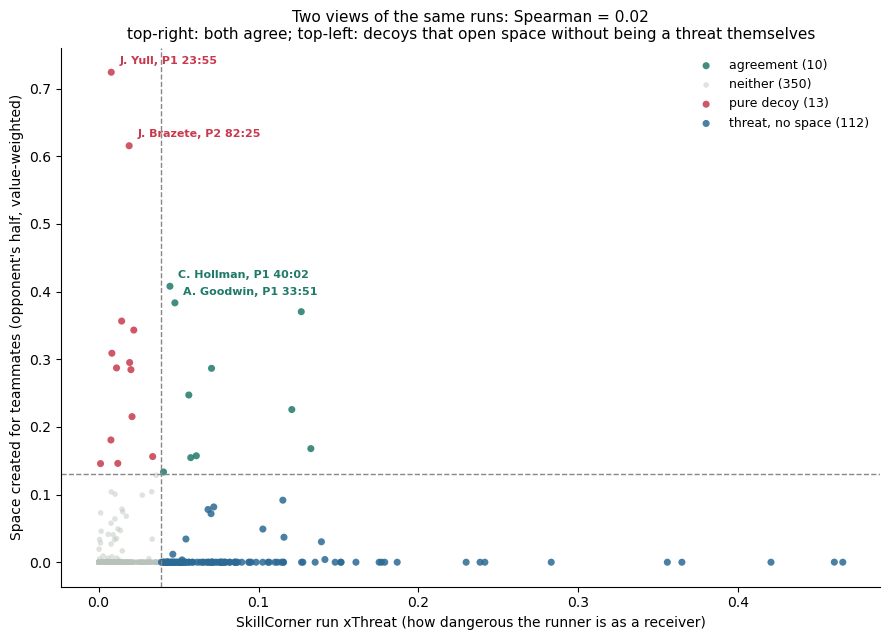

Top agreement examples


,team,player,clock,match_id,run_type,space,sk_xthreat,sk_dangerous
1383,Sydney FC,C. Hollman,P1 40:02,1996435,support,0.408,0.045,True
1061,Adelaide United,A. Goodwin,P1 33:51,1996435,cross_receiver,0.383,0.048,True
1248,Sydney FC,A. Ouahim,P2 67:17,1996435,cross_receiver,0.370,0.127,True


Top pure decoy examples


,team,player,clock,match_id,run_type,space,sk_xthreat,sk_dangerous
1023,Adelaide United,J. Yull,P1 23:55,1996435,run_ahead_of_the_ball,0.724,0.008,False
464,Brisbane FC,J. Brazete,P2 82:25,1925299,run_ahead_of_the_ball,0.616,0.019,False
1138,Adelaide United,R. White,P2 92:23,1996435,run_ahead_of_the_ball,0.357,0.014,False


In [8]:
XT_Q = 0.75                    # "high" = at or above this quantile on each axis
XT_EXAMPLES = 3                # examples rendered per highlighted quadrant
XT_DIR = FIG_DIR / "xthreat"
XT_DIR.mkdir(parents=True, exist_ok=True)

X = RUNS[(RUNS.kind == "off_ball") & RUNS.sk_xthreat.notna()].copy()
X["sk_xthreat"] = X.sk_xthreat.astype(float)
X["space"] = X.created_opp_half.clip(lower=0)
positive = X.space[X.space > 0]
SPACE_CUT = float(positive.quantile(XT_Q)) if len(positive) else 0.0
XT_CUT = float(X.sk_xthreat.quantile(XT_Q))
hi_s, hi_x = (X.space >= SPACE_CUT) & (X.space > 0), X.sk_xthreat >= XT_CUT
X["quadrant"] = np.select([hi_s & hi_x, hi_s & ~hi_x, ~hi_s & hi_x],
                          ["agreement", "pure decoy", "threat, no space"], "neither")
rho = spearmanr(X.space, X.sk_xthreat)[0]
print(f"{len(X):,} off-ball runs matched to SkillCorner. Spearman(space created, run xThreat) = {rho:.2f}")
print(f"High space created: >= {SPACE_CUT:.3f}; high xThreat: >= {XT_CUT:.3f}")
display(X.groupby("quadrant").agg(runs=("space", "size"), mean_space=("space", "mean"), mean_xthreat=("sk_xthreat", "mean"),
                                 sk_dangerous=("sk_dangerous", lambda s: (s == True).mean())).round(3))


@lru_cache(maxsize=None)
def _period_starts(mid):
    z = np.load(CACHE_DIR / f"{mid}_tracking.npz", allow_pickle=True)
    return {int(p): int(z["frames"][z["period"] == p].min()) for p in np.unique(z["period"])}


def clock(mid, frame, period):
    secs = (int(frame) - _period_starts(int(mid))[int(period)]) / FPS + (45 * 60 if int(period) == 2 else 0)
    return f"P{int(period)} {int(secs // 60):02d}:{int(secs % 60):02d}"


X["player"] = X.player_id.map(mins["name"])
X["team"] = X.team_id.map(team_names)
X["clock"] = [clock(m, f, p) for m, f, p in zip(X.match_id, X.frame_start, X.period)]
top = {q: X[X.quadrant == q].sort_values(["space", "sk_xthreat"], ascending=[False, q == "agreement"])
       .groupby("player_id").head(1).head(XT_EXAMPLES) for q in ("agreement", "pure decoy")}

# ---- the figure ----
colours = {"agreement": "#1f7a6a", "pure decoy": "#c8394e", "threat, no space": "#2b6a94", "neither": "#b9c2ba"}
fig, ax = plt.subplots(figsize=(9, 6.5))
for q, g in X.groupby("quadrant"):
    ax.scatter(g.sk_xthreat, g.space, s=16 if q == "neither" else 26, c=colours[q], alpha=.45 if q == "neither" else .85,
               label=f"{q} ({len(g)})", edgecolors="none")
ax.axvline(XT_CUT, color="#888", ls="--", lw=1)
ax.axhline(SPACE_CUT, color="#888", ls="--", lw=1)
for q in ("agreement", "pure decoy"):
    for r in top[q].head(2).itertuples():
        ax.annotate(f"{r.player}, {r.clock}", (r.sk_xthreat, r.space), xytext=(6, 6), textcoords="offset points",
                    fontsize=8, color=colours[q], weight="bold")
ax.set_xlabel("SkillCorner run xThreat (how dangerous the runner is as a receiver)")
ax.set_ylabel("Space created for teammates (opponent's half, value-weighted)")
ax.set_title(f"Two views of the same runs: Spearman = {rho:.2f}\n"
             f"top-right: both agree; top-left: decoys that open space without being a threat themselves", fontsize=11)
ax.legend(frameon=False, fontsize=9, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(XT_DIR / "xthreat_quadrants.png", dpi=160)
plt.show()

cols = ["team", "player", "clock", "match_id", "run_type", "space", "sk_xthreat", "sk_dangerous"]
for q in ("agreement", "pure decoy"):
    print(f"Top {q} examples")
    display(top[q][cols].round(3))
X.drop(columns=["path", "defence_map", "attack_map"], errors="ignore").to_csv(XT_DIR / "xthreat_quadrants.csv", index=False)

In [9]:
# Stills and GIFs for the top examples in the two highlighted quadrants (saved to figures/xthreat/)
rows = []
_show = plt.show
plt.show = lambda *a, **k: plt.close("all")
try:
    for q in ("agreement", "pure decoy"):
        for n, (mid, g) in enumerate(top[q].groupby("match_id")):
            ctx = build_ctx(mid)
            for run in g.itertuples():
                tag = f"{q.replace(' ', '_')}_{run.match_id}_{run.frame_start}"
                _, ben = plot_run_case(run, ctx)
                shutil.copy(FIG_DIR / "cases" / f"{run.kind}_{run.match_id}_{run.frame_end}.png", XT_DIR / f"{tag}.png")
                animate_run(run, ctx, fname=f"../xthreat/{tag}.gif")
                rows.append(dict(quadrant=q, player=run.player, team=run.team, clock=run.clock, space=round(run.space, 3),
                                 sk_xthreat=round(run.sk_xthreat, 3), beneficiary=ben["name"] if ben else None,
                                 file=f"{tag}.gif"))
finally:
    plt.show = _show
display(pd.DataFrame(rows))

,quadrant,player,team,clock,space,sk_xthreat,beneficiary,file
0,agreement,C. Hollman,Sydney FC,P1 40:02,0.408,0.045,A. Cáceres,agreement_1996435_24036.gif
1,agreement,A. Goodwin,Adelaide United,P1 33:51,0.383,0.048,J. Yull,agreement_1996435_20322.gif
2,agreement,A. Ouahim,Sydney FC,P2 67:17,0.370,0.127,A. Cáceres,agreement_1996435_41400.gif
3,pure decoy,J. Brazete,Brisbane FC,P2 82:25,0.616,0.019,J. O'Shea,pure_decoy_1925299_52700.gif
4,pure decoy,J. Yull,Adelaide United,P1 23:55,0.724,0.008,S. Mauk,pure_decoy_1996435_14360.gif
5,pure decoy,R. White,Adelaide United,P2 92:23,0.357,0.014,L. Jovanovic,pure_decoy_1996435_56466.gif


## 5. Validation

Does the model describe what actually happens? Each check below gives an **absolute number with a baseline**, so the
findings can be stated plainly. The heavy work is one pass per match (5.2), cached to disk; everything after it reads
that cache. Every check adds a row to the **validation scorecard** in Section 9.

| | Check | Question |
|---|---|---|
| 5.1 | Run detection vs SkillCorner | Do we find the runs SkillCorner tags, and do its dangerous runs create more space? |
| 5.2 | Per-match validation pass | (computes the evidence for 5.3–5.8) |
| 5.3 | Next-pass test | Does the ball go to the predicted runner, and into the green, more than chance? |
| 5.4 | SkillCorner passing options | Is the predicted runner a SkillCorner passing option? Are options in our space more valuable? |
| 5.5 | Pass outcomes | Are passes into created space completed and line-breaking more often? |
| 5.6 | Defensive-line flags and run types | Do runs SkillCorner says pushed the line pull defenders in our model? |
| 5.7 | Possession outcomes | Do team plays that create space lead to shots and final-third entries more often? |
| 5.8 | Expected-spot accuracy | How close are defenders to their expected spots in normal play, vs simple baselines? |
| 5.9 | Placebo | Do random moments "create space" as often as real runs? |
| 5.10 | Split-half stability | Is space creation a repeatable player trait? |
| 5.11 | Sensitivity | Do the results survive changes to the thresholds? |

In [10]:
from collections import namedtuple
from scipy.stats import mannwhitneyu, fisher_exact

SC = {}                      # validation scorecard rows, filled by each check and shown in Section 9


def wilson(k, n, z=1.96):
    """Share k/n with a 95% Wilson interval, as (share, low, high)."""
    if not n:
        return (np.nan, np.nan, np.nan)
    p = k / n
    d = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
    return (p, c - h, c + h)


def pct(p):
    return "NA" if p is None or pd.isna(p) else f"{100 * p:.0f}%"


def pct_ci(k, n):
    p, lo, hi = wilson(k, n)
    return "NA" if not n else f"{100 * p:.0f}% ({100 * lo:.0f}–{100 * hi:.0f}%, n={n})"


def add_score(key, check, result, comparison, shows):
    SC[key] = dict(check=check, result=result, comparison=comparison, shows=shows)


print("Validation helpers ready")

Validation helpers ready


### 5.1 Run detection vs SkillCorner, by run type

Recall of SkillCorner's tagged off-ball runs by run type (which kinds of run the tracking detection misses), and a test
of the earlier finding that SkillCorner's *dangerous* runs create more space (one-sided Mann-Whitney).

In [11]:
sk_runs = events_all[events_all.event_type == "off_ball_run"].copy()
_found = set(zip(RUNS.match_id, RUNS.sk_event_id.astype(str)))          # event ids are only unique within a match
sk_runs["found"] = [(m, str(e)) in _found for m, e in zip(sk_runs.match_id, sk_runs.event_id)]
by_type = (sk_runs.groupby("event_subtype").agg(runs=("found", "size"), recall=("found", "mean"),
                                                 median_speed_kmh=("speed_avg", "median"))
           .sort_values("recall"))
display(by_type.round(2))
recall_all = sk_runs.found.mean()
precision_all = RUNS[RUNS.kind == "off_ball"].sk_event_id.notna().mean()

m = RUNS[(RUNS.kind == "off_ball") & RUNS.sk_dangerous.notna()]
dang, nond = m[m.sk_dangerous == True].created, m[m.sk_dangerous == False].created
p_dang = mannwhitneyu(dang, nond, alternative="greater").pvalue if len(dang) > 5 and len(nond) > 5 else np.nan
print(f"Recall {recall_all:.0%}, precision {precision_all:.0%}. Mean space created: dangerous {dang.mean():.3f} "
      f"vs other {nond.mean():.3f} (one-sided Mann-Whitney p = {p_dang:.3g})")
add_score("detect", "Runs found vs SkillCorner's tagged runs", f"{recall_all:.0%} recall, {precision_all:.0%} precision",
          "SkillCorner Dynamic Events off-ball runs", "How much of SkillCorner's run list we recover")
add_score("dangerous", "SkillCorner 'dangerous' runs create more space",
          f"{dang.mean():.3f} vs {nond.mean():.3f}", f"other matched runs (p = {p_dang:.2g})",
          "Agreement with an independent danger label")

,runs,recall,median_speed_kmh
event_subtype,,,
pulling_half_space,294,0.02,16.88
coming_short,1274,0.03,16.69
dropping_off,1097,0.04,16.68
support,1653,0.04,17.73
pulling_wide,645,0.05,17.32
behind,749,0.05,20.22
run_ahead_of_the_ball,2716,0.06,18.39
cross_receiver,936,0.07,18.78
overlap,301,0.08,20.54


Recall 5%, precision 47%. Mean space created: dangerous 0.004 vs other 0.014 (one-sided Mann-Whitney p = 0.971)


### 5.2 Per-match validation pass

One pass over each match (cached; set `VAL_REBUILD = True` to redo it). For every movement that pulled a defender and
was followed by a pass within `NEXT_PASS_MAX_S` of the movement ending, at the moment the ball is played it records:
the model's ranking of who should run into the space (the passer excluded), who actually received, simple baselines
(most open teammate, nearest teammate to the ball, random eligible teammate), whether the pass landed in the green,
and which teammates SkillCorner tagged as passing options. It also samples calm moments for expected-spot accuracy,
random placebo moments, and a few movements to re-score under different thresholds.

In [12]:
VAL_REBUILD = False            # True to recompute the per-match validation pass
NEXT_PASS_MAX_S = 3.0          # pass must be released within this of the movement ending
GREEN_REACH_M = 40.0           # chance baseline for "into the green": share of cells within this of the ball
OPTION_TOL = 5                 # frames of tolerance when matching SkillCorner passing options to a moment
EXP_STRIDE = 100               # expected-spot accuracy: one sampled frame every 10 s...
CALM_PAD = 20                  # ...skipping frames within 2 s of an abnormal movement by the team in possession
PLACEBO_PER_MATCH = 15         # random placebo moments per match
SENS_PER_MATCH = 8             # movements per match re-scored under other thresholds
SENS_VARIANTS = [("ABNORMAL_MIN_M", 2.0), ("ABNORMAL_MIN_M", 4.0), ("DEV_GROWTH_MIN", 0.5), ("DEV_GROWTH_MIN", 1.5),
                 ("OCCUPIED_R", 4.0), ("OCCUPIED_R", 6.0)]
VAL_DIR = FIG_DIR / "validation"
VAL_DIR.mkdir(parents=True, exist_ok=True)
VAL_CACHE = OUT_DIR / f"validation_pass_{PIPELINE_VERSION}.pkl"

FakeRun = namedtuple("FakeRun", "Index idx_start idx_end player_id team_id kind dx dy match_id dragged_ids")
_po = events_all[events_all.event_type == "passing_option"]
OPTIONS = {k: g for k, g in _po.groupby(["match_id", "team_id"])}


def eligible_ids(ctx, st, exclude):
    trk = ctx.trk
    return [int(trk.player_ids[k]) for k in st["att"] if int(trk.player_ids[k]) not in exclude
            and ROLE_GROUP.get(ctx.role.get(trk.player_ids[k]), "OTHER") not in BEN_EXCLUDE_GROUPS
            and ctx.role.get(trk.player_ids[k]) != "GK" and not np.isnan(st["pos"][k, 0])]


def calm_mask(trk, runs_m):
    """True where the team in possession has no abnormal movement within CALM_PAD frames."""
    busy = {}
    ab = runs_m[runs_m.abnormal] if "abnormal" in runs_m else runs_m
    for r in ab.itertuples():
        m = busy.setdefault(int(r.team_id), np.zeros(len(trk.frames), bool))
        m[max(int(r.idx_start) - CALM_PAD, 0):int(r.idx_end) + CALM_PAD + 1] = True
    calm = np.ones(len(trk.frames), bool)
    for t, m in busy.items():
        calm &= ~((trk.poss_team == t) & m)
    return calm


def eval_movement(ctx, run, opts):
    trk, g = ctx.trk, ctx.grid
    pinfo = pass_info(ctx, run)
    rec = dict(idx=int(run.Index), match_id=int(run.match_id), player_id=int(run.player_id), team_id=int(run.team_id),
               frame_start=int(run.frame_start), kind=run.kind, has_pass=False)
    if pinfo is None or pinfo["idx"] > int(run.idx_end) + NEXT_PASS_MAX_S * FPS:
        return rec, []
    i, passer, receiver = pinfo["idx"], pinfo["passer"], pinfo["receiver"]
    sc = run_scene(ctx, run, i, with_created=True)
    created = np.clip(sc["created"], 0, None)
    st = frame_state(trk, i, int(run.team_id))
    P = st["pos"]
    elig = eligible_ids(ctx, st, {int(run.player_id), passer})
    ben = find_beneficiary(ctx, run, i, sc["created"], exclude_pids=[passer])
    order = [int(p) for p in ben["ranking"].player_id] if ben is not None else []
    col = {int(trk.player_ids[k]): k for k in st["att"]}
    dmin = {p: float(np.nanmin(np.linalg.norm(P[st["dfn"]] - P[col[p]], axis=1))) for p in elig}
    dball = {p: float(np.linalg.norm(P[col[p]] - st["ball"])) for p in elig}
    f = int(trk.frames[i])
    o = opts[(opts.frame_start - OPTION_TOL <= f) & (opts.frame_end + OPTION_TOL >= f)] if opts is not None else None
    opt_ids = set(int(p) for p in o.player_id) if o is not None and len(o) else set()
    reach = np.linalg.norm(g.points - st["ball"], axis=1) <= GREEN_REACH_M
    green = created >= CREATED_MAP_THRESHOLD
    cell = g.cell(pinfo["target"])[0]
    dev = np.linalg.norm(sc["drag_now"] - sc["drag_exp"], axis=1) if len(sc["drag_now"]) else np.zeros(0)
    rec.update(has_pass=True, pass_frame=f, passer=passer, receiver=receiver, completed=pinfo["completed"],
               n_eligible=len(elig), receiver_eligible=receiver in elig,
               has_beneficiary=ben is not None, ben_id=order[0] if order else np.nan,
               receiver_rank=(order.index(receiver) + 1) if receiver in order else np.nan,
               hit_top1=bool(order) and order[0] == receiver, hit_top2=receiver in order[:2],
               hit_open=bool(elig) and max(elig, key=dmin.get) == receiver,
               hit_nearest=bool(elig) and min(elig, key=dball.get) == receiver,
               chance=1 / len(elig) if elig else np.nan,
               into_green=bool(green[cell]), green_share=float(green[reach].mean()) if reach.any() else np.nan,
               ben_is_option=bool(order) and order[0] in opt_ids,
               option_share=float(np.mean([p in opt_ids for p in elig])) if elig else np.nan,
               receiver_was_option=receiver in opt_ids,
               max_drag_dev=float(np.nanmax(dev)) if len(dev) else np.nan)
    orows = []
    if o is not None:
        for r in o.itertuples():
            k = col.get(int(r.player_id))
            if k is None or np.isnan(P[k, 0]):
                continue
            orows.append(dict(match_id=int(run.match_id), idx=int(run.Index), player_id=int(r.player_id),
                              in_green=bool(green[g.cell(P[k])[0]]), created_here=float(created[g.cell(P[k])[0]]),
                              xthreat=r.xthreat, xpass_completion=r.xpass_completion, received=r.received,
                              targeted=r.targeted))
    return rec, orows


def expected_errors(ctx, runs_m):
    trk = ctx.trk
    calm = calm_mask(trk, runs_m)
    rows = []
    for i in np.flatnonzero((trk.poss_team != -1) & ~np.isnan(trk.ball[:, 0]) & calm)[::EXP_STRIDE]:
        st = frame_state(trk, int(i))
        P = st["pos"]
        dfn = [k for k in st["dfn"] if ctx.role.get(trk.player_ids[k]) != "GK" and not np.isnan(P[k, 0])]
        if len(dfn) < 5:
            continue
        E = ctx.expected(dfn, "out", st["ball"], trk.phase[i], P)
        for n, k in enumerate(dfn):
            others = [q for q in dfn if q != k]
            centre = P[others].mean(0)
            rows.append(dict(match_id=trk.match_id, frame=int(trk.frames[i]), role=ctx.role.get(trk.player_ids[k]),
                             x=P[k, 0], y=P[k, 1], ox=P[k, 0] - centre[0], oy=P[k, 1] - centre[1],
                             cx=centre[0], cy=centre[1], err_model=float(np.linalg.norm(P[k] - E[n]))))
    return rows


def with_settings(changes, fn):
    """Run fn() with some core settings temporarily changed (scoring reads them from the core module)."""
    old = {k: getattr(core, k) for k in changes}
    try:
        for k, v in changes.items():
            setattr(core, k, v)
        return fn()
    finally:
        for k, v in old.items():
            setattr(core, k, v)


def placebo_moments(ctx, runs_m, rng):
    trk = ctx.trk
    calm = calm_mask(trk, runs_m)
    durs = (runs_m.idx_end - runs_m.idx_start).clip(5, 40).values if len(runs_m) else np.array([10])
    cand = np.flatnonzero((trk.poss_team != -1) & np.isin(trk.phase, list(BUILDUP_PHASES)) & calm)
    rows, tries = [], 0
    while len(rows) < PLACEBO_PER_MATCH and tries < PLACEBO_PER_MATCH * 20 and len(cand):
        tries += 1
        e = int(rng.choice(cand))
        a = e - int(rng.choice(durs))
        if a < 0 or trk.period[a] != trk.period[e] or trk.poss_team[a] != trk.poss_team[e]:
            continue
        team = int(trk.poss_team[e])
        js = [j for j in np.flatnonzero(trk.team_ids == team) if ctx.role.get(trk.player_ids[j]) != "GK"
              and not np.isnan(trk.pos[a:e + 1, j, 0]).any()]
        if not js:
            continue
        j = int(rng.choice(js))
        s = trk.direction.get((team, int(trk.period[a])), 1)
        d = (trk.pos[e, j] - trk.pos[a, j]) * s
        fake = FakeRun(-1 - len(rows), a, e, int(trk.player_ids[j]), team, "off_ball", float(d[0]), float(d[1]),
                       trk.match_id, [])
        res = with_settings({"ABNORMAL_MIN_M": 0.0}, lambda: score_run(ctx, fake))
        rows.append(dict(match_id=trk.match_id, frame=int(trk.frames[e]), created=res["created"],
                         n_dragged=res["n_dragged"]))
    return rows


def sensitivity_rows(ctx, runs_m, rng):
    ab = runs_m[runs_m.abnormal] if "abnormal" in runs_m else runs_m
    if not len(ab):
        return []
    rows = []
    for run in ab.sample(min(SENS_PER_MATCH, len(ab)), random_state=int(rng.integers(1 << 30))).itertuples():
        rec = dict(match_id=int(run.match_id), idx=int(run.Index), default=score_run(ctx, run)["created"])
        for k, v in SENS_VARIANTS:
            rec[f"{k}={v:g}"] = with_settings({k: v}, lambda: score_run(ctx, run))["created"]
        rows.append(rec)
    return rows


def validate_match(mid, rng):
    ctx = build_ctx(mid)
    runs_m = RUNS[RUNS.match_id == mid]
    out = dict(evals=[], options=[], expected=[], placebo=[], sens=[])
    for run in runs_m[runs_m.n_dragged > 0].itertuples():
        rec, orows = eval_movement(ctx, run, OPTIONS.get((mid, int(run.team_id))))
        out["evals"].append(rec)
        out["options"] += orows
    out["expected"] = expected_errors(ctx, runs_m)
    out["placebo"] = placebo_moments(ctx, runs_m, rng)
    out["sens"] = sensitivity_rows(ctx, runs_m, rng)
    return out


if VAL_CACHE.exists() and not VAL_REBUILD:
    VPASS = pd.read_pickle(VAL_CACHE)
    print(f"Loaded the validation pass from {VAL_CACHE.name}")
else:
    rng = np.random.default_rng(RANDOM_STATE)
    acc = dict(evals=[], options=[], expected=[], placebo=[], sens=[])
    for mid in match_ids:
        try:
            r = validate_match(mid, rng)
            for k in acc:
                acc[k] += r[k]
            n_pass = sum(1 for e in r["evals"] if e["has_pass"])
            print(f"{mid}: {len(r['evals'])} credited movements ({n_pass} followed by a pass), "
                  f"{len(r['expected'])} defender samples, {len(r['placebo'])} placebo moments", flush=True)
        except Exception as exc:
            print(f"{mid}: FAILED — {exc!r}")
    VPASS = {k: pd.DataFrame(v) for k, v in acc.items()}
    pd.to_pickle(VPASS, VAL_CACHE)
EV = VPASS["evals"]
NP = EV[EV.has_pass] if len(EV) else EV
print(f"{len(EV):,} credited movements evaluated, {len(NP):,} followed by a pass")

1874553: 0 credited movements (0 followed by a pass), 3340 defender samples, 15 placebo moments
1886347: 0 credited movements (0 followed by a pass), 3250 defender samples, 15 placebo moments
1899585: 0 credited movements (0 followed by a pass), 2990 defender samples, 15 placebo moments
1925299: 222 credited movements (177 followed by a pass), 1290 defender samples, 15 placebo moments
1927964: 0 credited movements (0 followed by a pass), 3740 defender samples, 15 placebo moments
1953632: 0 credited movements (0 followed by a pass), 3310 defender samples, 15 placebo moments
1959846: 0 credited movements (0 followed by a pass), 3110 defender samples, 15 placebo moments
1986691: 0 credited movements (0 followed by a pass), 3130 defender samples, 15 placebo moments
1996435: 265 credited movements (184 followed by a pass), 960 defender samples, 15 placebo moments
1996436: 0 credited movements (0 followed by a pass), 2850 defender samples, 15 placebo moments
2006229: 0 credited movements (0 

### 5.3 Next-pass test

At the moment the ball is played, does it go to the teammate the model said should run into the space? Compared with
three baselines over the same eligible teammates (not the mover, the passer, centre-backs or the keeper): the most open
teammate, the nearest teammate to the ball, and a random pick. Also: does the pass land in the green, compared with
the share of reachable pitch that is green at that moment?

In [13]:
if len(NP):
    n = len(NP)
    chance = NP.chance.mean()
    tab = pd.DataFrame({
        "ball went to them": [pct_ci(NP.hit_top1.sum(), n), pct_ci(NP.hit_top2.sum(), n), pct_ci(NP.hit_open.sum(), n),
                              pct_ci(NP.hit_nearest.sum(), n), f"{chance:.0%} (expected by chance)"]},
        index=["Model's predicted runner", "Model's top two", "Most open teammate", "Nearest teammate to the ball",
               "Random eligible teammate"])
    display(tab)
    exp_hits, var = NP.chance.sum(), (NP.chance * (1 - NP.chance)).sum()
    z = (NP.hit_top1.sum() - exp_hits) / np.sqrt(var) if var > 0 else np.nan
    to_elig = NP[NP.receiver_eligible]
    print(f"Passes to an eligible teammate only: predicted runner {pct_ci(to_elig.hit_top1.sum(), len(to_elig))}, "
          f"chance {to_elig.chance.mean():.0%}. Observed vs chance: z = {z:.1f}")
    print(f"Pass landed in the green: {pct_ci(NP.into_green.sum(), n)}; green share of reachable pitch "
          f"{NP.green_share.mean():.0%}")
    comp = NP.groupby("hit_top1").completed.mean()
    print(f"Completion: to the predicted runner {pct(comp.get(True))}, to anyone else {pct(comp.get(False))}")
    add_score("nextpass", "Ball goes to the predicted runner", pct_ci(NP.hit_top1.sum(), n),
              f"{chance:.0%} by chance; most open {pct(NP.hit_open.mean())}; nearest {pct(NP.hit_nearest.mean())}",
              "The 'who should go where' arrow predicts real passes")
    add_score("green", "Pass lands in the green", pct_ci(NP.into_green.sum(), n),
              f"{NP.green_share.mean():.0%} of reachable pitch is green", "The opened space is where the ball goes")
else:
    print("No credited movements followed by a pass — nothing to test")

,ball went to them
Model's predicted runner,"14% (11–18%, n=361)"
Model's top two,"25% (20–29%, n=361)"
Most open teammate,"10% (7–13%, n=361)"
Nearest teammate to the ball,"31% (27–36%, n=361)"
Random eligible teammate,15% (expected by chance)


Passes to an eligible teammate only: predicted runner 19% (15–24%, n=270), chance 15%. Observed vs chance: z = -0.3
Pass landed in the green: 2% (1–5%, n=361); green share of reachable pitch 1%
Completion: to the predicted runner 90%, to anyone else 80%


### 5.4 SkillCorner passing options

SkillCorner tags every moment a player is a realistic passing option. If the model's predicted runner is real, he should
be one more often than a random eligible teammate. And passing options standing in our green should be worth more
(SkillCorner xThreat) than options elsewhere.

In [14]:
OPT = VPASS["options"]
if len(NP):
    k, n = int(NP.ben_is_option.sum()), int(NP.has_beneficiary.sum())
    print(f"Predicted runner was a SkillCorner passing option: {pct_ci(k, n)}; a random eligible teammate: "
          f"{NP.option_share.mean():.0%}. Receiver was an option: {pct(NP.receiver_was_option.mean())}")
    add_score("options", "Predicted runner is a SkillCorner passing option", pct_ci(k, n),
              f"{NP.option_share.mean():.0%} for a random eligible teammate", "Agreement with SkillCorner's options")
if len(OPT):
    g_in, g_out = OPT[OPT.in_green], OPT[~OPT.in_green]
    tab = OPT.groupby("in_green").agg(options=("xthreat", "size"), mean_xthreat=("xthreat", "mean"),
                                      mean_xpass=("xpass_completion", "mean"),
                                      received=("received", lambda s: (s == True).mean()))
    tab.index = tab.index.map({True: "in our green", False: "elsewhere"})
    display(tab.round(3))
    p_opt = (mannwhitneyu(g_in.xthreat.dropna(), g_out.xthreat.dropna(), alternative="greater").pvalue
             if len(g_in) > 5 and len(g_out) > 5 else np.nan)
    print(f"xThreat of options in the green vs elsewhere: one-sided Mann-Whitney p = {p_opt:.3g}")
    if len(g_in) > 5:
        add_score("option_value", "SkillCorner options in our green are worth more",
                  f"xThreat {g_in.xthreat.mean():.3f} vs {g_out.xthreat.mean():.3f} (n = {len(g_in)})",
                  f"options elsewhere (p = {p_opt:.2g})", "Our space lines up with SkillCorner's valuation")
    else:
        print(f"Only {len(g_in)} SkillCorner options in the green: too few to compare (left off the scorecard)")

Predicted runner was a SkillCorner passing option: 33% (28–38%, n=361); a random eligible teammate: 27%. Receiver was an option: 99%


,options,mean_xthreat,mean_xpass,received
in_green,,,,
elsewhere,833,0.019,0.793,0.346
in our green,16,0.018,0.812,0.375


xThreat of options in the green vs elsewhere: one-sided Mann-Whitney p = 0.134


### 5.5 Pass outcomes

Are passes into created space completed more often, and more often line-breaking? Compared within the same pass
range and target third, so long balls into the final third aren't compared with short passes at the back.

In [15]:
PP = PASSES.copy()
PP["third"] = pd.cut(PP.target_x, [-60, -17.5, 17.5, 60], labels=["defensive", "middle", "final"])
PP["line_break"] = PP.sk_line_break.astype(bool)
rows = []
for (rng_, third), g in PP.groupby(["pass_range", "third"], observed=True):
    a, b = g[g.into_created_space], g[~g.into_created_space]
    if len(a) >= 3 and len(b) >= 3:
        rows.append(dict(pass_range=rng_, third=third, n_into=len(a), n_other=len(b),
                         completion_diff=a.completed.mean() - b.completed.mean(),
                         line_break_diff=a.line_break.mean() - b.line_break.mean(),
                         value_diff=a.target_value.mean() - b.target_value.mean()))
STRAT = pd.DataFrame(rows)
if len(STRAT):
    w = STRAT.n_into / STRAT.n_into.sum()
    cd, ld = float((STRAT.completion_diff * w).sum()), float((STRAT.line_break_diff * w).sum())
    display(STRAT.round(3))
    print(f"Weighted over matched strata: completion {cd:+.1%}, line-break rate {ld:+.1%} for passes into created space")
    add_score("pass_outcomes", "Passes into created space", f"completion {cd:+.0%}, line breaks {ld:+.0%}",
              "other passes of the same range into the same third", "Space we find is space that works")
else:
    print("Not enough passes into created space in matched strata")

,pass_range,third,n_into,n_other,completion_diff,line_break_diff,value_diff
0,short,middle,4,392,0.0,-0.135,0.004
1,short,final,3,242,0.0,-0.095,0.002


Weighted over matched strata: completion +0.0%, line-break rate -11.8% for passes into created space


### 5.6 Defensive-line flags and run types

SkillCorner flags some runs as having **pushed** or **broken** the defensive line (filled for a minority of runs).
Those runs should pull back-line defenders in our model more often. And decoy-style run types (pulling wide, pulling
half-space, dropping off) should pull defenders more often than runs in behind.

In [16]:
flags = (sk_runs.assign(sk_event_id=sk_runs.event_id.astype(str))
         [["match_id", "sk_event_id", "push_defensive_line", "break_defensive_line", "event_subtype"]])
MR = (RUNS[(RUNS.kind == "off_ball") & RUNS.sk_event_id.notna()].assign(sk_event_id=lambda d: d.sk_event_id.astype(str))
      .reset_index().merge(flags, on=["match_id", "sk_event_id"], how="left").set_index("index"))
role_of = dict(zip(players_all.player_id, players_all.role))
MR["pulled_any"] = MR.n_dragged > 0
MR["pulled_back_line"] = MR.dragged_ids.apply(lambda ids: any(role_of.get(int(d)) in DEFENDER_ROLES for d in ids))
for flag in ("push_defensive_line", "break_defensive_line"):
    f = MR[MR[flag].notna()]
    if len(f) and f[flag].astype(bool).nunique() == 2:
        t, o = f[f[flag].astype(bool)], f[~f[flag].astype(bool)]
        odds, p = fisher_exact([[t.pulled_back_line.sum(), (~t.pulled_back_line).sum()],
                                [o.pulled_back_line.sum(), (~o.pulled_back_line).sum()]], alternative="greater")
        print(f"{flag}: pulled a back-line defender in {pct_ci(t.pulled_back_line.sum(), len(t))} of flagged runs vs "
              f"{pct_ci(o.pulled_back_line.sum(), len(o))} of unflagged (Fisher p = {p:.3g})")
        if flag == "push_defensive_line":
            add_score("line_flag", "Runs SkillCorner says pushed the line pull a back-line defender",
                      pct(t.pulled_back_line.mean()), f"{pct(o.pulled_back_line.mean())} of unflagged runs (p = {p:.2g})",
                      "Our drag rule agrees with SkillCorner's line flags")
    else:
        print(f"{flag}: not enough flagged runs to compare")
display(MR.groupby("event_subtype").agg(runs=("pulled_any", "size"), pulled_a_defender=("pulled_any", "mean"),
                                        mean_space=("created", "mean")).sort_values("pulled_a_defender",
                                                                                   ascending=False).round(3))

push_defensive_line: pulled a back-line defender in 62% (39–82%, n=16) of flagged runs vs 33% (17–55%, n=21) of unflagged (Fisher p = 0.076)
break_defensive_line: pulled a back-line defender in 29% (8–64%, n=7) of flagged runs vs 50% (33–67%, n=30) of unflagged (Fisher p = 0.928)


,runs,pulled_a_defender,mean_space
event_subtype,,,
behind,37,0.486,0.024
pulling_wide,30,0.367,0.018
cross_receiver,61,0.328,-0.007
underlap,24,0.292,0.051
coming_short,34,0.235,0.006
support,73,0.219,0.007
run_ahead_of_the_ball,152,0.211,0.012
pulling_half_space,6,0.167,0.003
dropping_off,43,0.116,0.004


### 5.7 Possession outcomes

Team plays (all movements by one team in a moment, until the pass) grouped by whether they created space. Outcomes in
the 10 seconds after the play ends: a shot by the same team, and (for plays starting outside it) reaching the final
third. Compared within the third the play started in.

In [17]:
OUT_WINDOW_S = 10
pp_ev = events_all[events_all.event_type == "player_possession"][["match_id", "team_id", "frame_start", "x_start", "end_type"]]
TPS = []
for mid in match_ids:
    T = build_team_plays(RUNS[RUNS.match_id == mid], PASSES[PASSES.match_id == mid] if len(PASSES) else PASSES)
    if len(T):
        TPS.append(T)
TP = pd.concat(TPS, ignore_index=True) if TPS else pd.DataFrame()
if len(TP):
    TP["start_x"] = TP.members.apply(lambda m: float(RUNS.loc[m[0], "x_start"]))
    TP["start_third"] = pd.cut(TP.start_x, [-60, -17.5, 17.5, 60], labels=["defensive", "middle", "final"])
    TP["created_space"] = TP.space > 0
    shot, ft = [], []
    by = {k: g for k, g in pp_ev.groupby(["match_id", "team_id"])}
    for t in TP.itertuples():
        g = by.get((t.match_id, t.team_id))
        w = g[(g.frame_start >= t.frame_end) & (g.frame_start <= t.frame_end + OUT_WINDOW_S * FPS)] if g is not None else None
        shot.append(bool(w is not None and (w.end_type == "shot").any()))
        ft.append(bool(w is not None and (w.x_start > 17.5).any()))
    TP["shot_10s"], TP["final_third_10s"] = shot, ft
    tab = (TP.groupby(["start_third", "created_space"], observed=True)
           .agg(plays=("shot_10s", "size"), shot_10s=("shot_10s", "mean"), final_third_10s=("final_third_10s", "mean")))
    display(tab.round(3))
    rows = []
    for third, g in TP.groupby("start_third", observed=True):
        a, b = g[g.created_space], g[~g.created_space]
        if len(a) >= 3 and len(b) >= 3:
            rows.append(dict(w=len(a), shot=a.shot_10s.mean() - b.shot_10s.mean(),
                             ft=(a.final_third_10s.mean() - b.final_third_10s.mean()) if third != "final" else np.nan))
    if rows:
        R_ = pd.DataFrame(rows)
        shot_d = float(np.average(R_.shot, weights=R_.w))
        ok = R_.ft.notna()
        ft_d = float(np.average(R_.ft[ok], weights=R_.w[ok])) if ok.any() else np.nan
        print(f"Within the same starting third: shot within 10 s {shot_d:+.1%}, final-third entry {ft_d:+.1%} "
              f"for plays that created space")
        add_score("possession", "Team plays that create space", f"shots {shot_d:+.0%}, final-third entries {ft_d:+.0%}",
                  "plays starting in the same third that created none", "Space leads somewhere")

plays  shot_10s  final_third_10s
start_third created_space                                  
defensive   False            212     0.024            0.057
            True              48     0.062            0.062
middle      False            341     0.076            0.340
            True             195     0.062            0.405
final       False            211     0.161            0.573
            True              94     0.138            0.649

Within the same starting third: shot within 10 s -0.9%, final-third entry +5.3% for plays that created space


### 5.8 Expected-spot accuracy

How far are defenders from their expected spots in **normal play** (no abnormal movement by the attacking team within
2 s)? Compared with two simpler baselines, each fitted without the match being tested: the role's average spot on the
pitch, and the role's average place relative to his team's block (no ball). The figure sets that normal-play error
against how far credited dragged defenders are from their spots, which is what makes a drag arrow meaningful.

,median error (m),within 5 m
Model (block + ball + phase),7.45,0.27
Block + role average offset,7.06,0.31
Role average spot,18.52,0.05


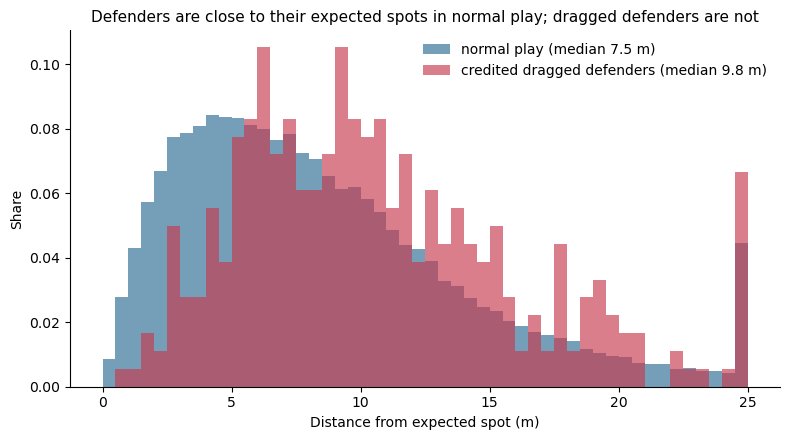

In [18]:
EX = VPASS["expected"]
if len(EX):
    errs = {"model": EX.err_model.values, "role average spot": [], "block + role average offset": []}
    b1, b2 = np.zeros(len(EX)), np.zeros(len(EX))
    for mid in EX.match_id.unique():
        tr, te = EX[EX.match_id != mid], EX.match_id == mid
        if not len(tr):
            tr = EX
        avg = tr.groupby("role")[["x", "y", "ox", "oy"]].mean()
        sub = EX[te]
        a = avg.reindex(sub.role).fillna(tr[["x", "y", "ox", "oy"]].mean())
        b1[te.values] = np.hypot(sub.x.values - a.x.values, sub.y.values - a.y.values)
        b2[te.values] = np.hypot(sub.ox.values - a.ox.values, sub.oy.values - a.oy.values)
    EX["err_role_avg"], EX["err_block_avg"] = b1, b2
    tab = pd.DataFrame({"median error (m)": [EX.err_model.median(), EX.err_block_avg.median(), EX.err_role_avg.median()],
                        "within 5 m": [(EX.err_model <= 5).mean(), (EX.err_block_avg <= 5).mean(),
                                       (EX.err_role_avg <= 5).mean()]},
                       index=["Model (block + ball + phase)", "Block + role average offset", "Role average spot"])
    display(tab.round(2))
    dd = EV.max_drag_dev.dropna() if "max_drag_dev" in EV else pd.Series(dtype=float)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    bins = np.linspace(0, 25, 51)
    ax.hist(EX.err_model.clip(upper=25), bins=bins, density=True, alpha=.65, color="#2b6a94",
            label=f"normal play (median {EX.err_model.median():.1f} m)")
    if len(dd):
        ax.hist(dd.clip(upper=25), bins=bins, density=True, alpha=.65, color="#c8394e",
                label=f"credited dragged defenders (median {dd.median():.1f} m)")
    ax.set_xlabel("Distance from expected spot (m)")
    ax.set_ylabel("Share")
    ax.set_title("Defenders are close to their expected spots in normal play; dragged defenders are not", fontsize=11)
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    fig.savefig(VAL_DIR / "expected_spot_accuracy.png", dpi=160)
    plt.show()
    add_score("expected", "Defenders' distance from expected spot in normal play",
              f"median {EX.err_model.median():.1f} m ({(EX.err_model <= 5).mean():.0%} within 5 m)",
              f"block baseline {EX.err_block_avg.median():.1f} m, role baseline {EX.err_role_avg.median():.1f} m; "
              f"dragged defenders median {dd.median():.1f} m" if len(dd) else "",
              "The hollow circles are a reliable reference")

### 5.9 Placebo

Random build-up moments with no abnormal movement, with a random outfield attacker treated as the "runner" over a
window as long as a real run, scored with the same drag rule (the abnormal-movement gate switched off so it can't zero
them by construction). Real runs should pull defenders far more often than these.

In [19]:
PL = VPASS["placebo"]
if len(PL):
    real = RUNS[RUNS.abnormal] if "abnormal" in RUNS else RUNS
    real_rate, pl_rate = (real.n_dragged > 0).mean(), (PL.n_dragged > 0).mean()
    print(f"Pulled a defender: real abnormal movements {real_rate:.0%} (n={len(real)}), placebo moments "
          f"{pct_ci(int((PL.n_dragged > 0).sum()), len(PL))}. Mean space created: real {real.created.mean():.3f}, "
          f"placebo {PL.created.mean():.3f}")
    add_score("placebo", "Random moments credited with a drag", pct_ci(int((PL.n_dragged > 0).sum()), len(PL)),
              f"{real_rate:.0%} of real abnormal movements", "The rule isn't crediting ordinary play")

Pulled a defender: real abnormal movements 35% (n=1391), placebo moments 2% (1–5%, n=300). Mean space created: real 0.023, placebo 0.000


### 5.10 Split-half stability

Each player's space created per 30 minutes of his team in possession, in odd- vs even-numbered matches. A repeatable
trait should correlate across the halves. With about 20 matches most players appear only a few times, so treat this as
indicative.

In [20]:
order = {m: k for k, m in enumerate(sorted(match_ids))}
RS = RUNS.assign(half=RUNS.match_id.map(lambda m: order[m] % 2))
mins_h = players_all.assign(half=players_all.match_id.map(lambda m: order[m] % 2)).groupby(["player_id", "half"]).minutes_tip.sum()
M = mins_h.unstack("half")
C = RS.groupby(["player_id", "half"]).created_opp_half.sum().unstack("half").reindex(M.index).fillna(0)
SH = (C / M * 30)[(M >= 30).all(axis=1)].dropna()
if len(SH) >= 5 and SH.shape[1] == 2:
    rho_sh = spearmanr(SH[0], SH[1])[0]
    print(f"Split-half Spearman across {len(SH)} players: {rho_sh:.2f}")
    add_score("stability", "Player space creation, odd vs even matches", f"Spearman {rho_sh:.2f} ({len(SH)} players)",
              "0 would mean pure noise", "Space creation is a repeatable trait")
else:
    print("Not enough players with minutes in both halves")

Split-half Spearman across 8 players: nan


### 5.11 Sensitivity

A sample of movements re-scored with each threshold moved up and down (one at a time). High rank correlation with the
default means the rankings don't hinge on the exact values. (The run-speed threshold needs a full rescore, so it isn't
included; see the settings log.)

In [21]:
SE = VPASS["sens"]
if len(SE):
    rows = []
    for c in [c for c in SE.columns if "=" in c]:
        rows.append(dict(variant=c, spearman_vs_default=spearmanr(SE.default, SE[c])[0] if SE[c].nunique() > 1 else np.nan,
                         share_credited=(SE[c] > 0).mean(), default_share=(SE.default > 0).mean()))
    SENS = pd.DataFrame(rows)
    display(SENS.round(2))
    add_score("sensitivity", "Rankings under other thresholds", f"Spearman {SENS.spearman_vs_default.min():.2f}–"
              f"{SENS.spearman_vs_default.max():.2f}", f"{len(SE)} movements, {len(SENS)} variants",
              "Conclusions don't hinge on exact settings")

,variant,spearman_vs_default,share_credited,default_share
0,ABNORMAL_MIN_M=2,1.00,0.25,0.25
1,ABNORMAL_MIN_M=4,0.95,0.25,0.25
2,DEV_GROWTH_MIN=0.5,1.00,0.25,0.25
3,DEV_GROWTH_MIN=1.5,0.95,0.19,0.25
4,OCCUPIED_R=4,0.89,0.25,0.25
5,OCCUPIED_R=6,0.99,0.25,0.25


### 5.12 Other checks against SkillCorner

Defensive-line height against SkillCorner's own last-line position, the link between space created and SkillCorner's
run xThreat (see Section 4), passer lead time against how long SkillCorner's passing option had existed, the run-type
classifier, and whether tracking quality changes the creator metric.

In [22]:
val = {"SkillCorner runs found by tracking detection (recall)": recall_all,
       "Tracking off-ball runs that match a SkillCorner run": precision_all}
m = RUNS.dropna(subset=["sk_xthreat"])
if len(m) > 10:
    val["Spearman: created space vs SkillCorner run xThreat"] = spearmanr(m.created, m.sk_xthreat.astype(float))[0]
skl = (events_all[events_all.event_type == "player_possession"]
       [["match_id", "frame_start", "team_id", "last_defensive_line_x_start"]].dropna()
       .rename(columns={"frame_start": "frame", "team_id": "team_att"}).sort_values("frame"))
lv = pd.merge_asof(LINE.sort_values("frame"), skl, on="frame", by=["match_id", "team_att"], tolerance=3,
                   direction="nearest").dropna(subset=["last_defensive_line_x_start"])
if len(lv):
    mae = (lv.line_x - lv.last_defensive_line_x_start).abs().mean()
    val["Line height: MAE vs SkillCorner (m)"] = mae
    val["Line height: correlation with SkillCorner"] = lv[["line_x", "last_defensive_line_x_start"]].corr().iat[0, 1]
    add_score("line_height", "Defensive line height vs SkillCorner", f"{mae:.1f} m mean error",
              "SkillCorner's last defensive line", "Coordinates and frames are handled correctly")
opt = (events_all[events_all.event_type == "passing_option"][["match_id", "event_id", "frame_start"]]
       .rename(columns={"event_id": "sk_option_event", "frame_start": "option_start"}))
opt["sk_option_event"] = opt.sk_option_event.astype(str)
lt = (PASSES.dropna(subset=["sk_option_event", "lead_s"]).assign(sk_option_event=lambda d: d.sk_option_event.astype(str))
      .merge(opt, on=["match_id", "sk_option_event"], how="inner"))
if len(lt) > 10:
    lt["option_age_s"] = (lt.frame_pass - lt.option_start) / FPS
    val["Spearman: lead time vs SK option age at release"] = spearmanr(lt.lead_s, lt.option_age_s)[0]
val["Run-type k-NN accuracy vs SkillCorner"] = RUNTYPE_ACC
display(pd.Series(val).round(3).to_frame("value"))
print("Does data quality change the creator metric? (mean created by runner detection rate)")
display(RUNS.groupby(pd.cut(RUNS.runner_detected, [0, .25, .5, .75, 1.0], include_lowest=True), observed=False)
        .created.agg(["mean", "count"]).round(4))

,value
SkillCorner runs found by tracking detection (recall),0.049
Tracking off-ball runs that match a SkillCorner run,0.470
Spearman: created space vs SkillCorner run xThreat,-0.067
Line height: MAE vs SkillCorner (m),0.398
Line height: correlation with SkillCorner,0.999
Spearman: lead time vs SK option age at release,-0.062
Run-type k-NN accuracy vs SkillCorner,NaN


Does data quality change the creator metric? (mean created by runner detection rate)


,mean,count
runner_detected,,
"(-0.001, 0.25]",0.0098,74
"(0.25, 0.5]",-0.0022,47
"(0.5, 0.75]",0.0170,54
"(0.75, 1.0]",0.0180,1669


## 6. Leaderboards and team comparison

Build-up phases only, reliable rows only (runner and dragged defenders mostly on camera), per 30 minutes of the
player's team being in possession. Sample size is fixed by the competition, so a minimum-minutes cut is applied
and team comparisons are exploratory.

In [23]:
mins = players_all.groupby("player_id").agg(name=("name", "first"), team_id=("team_id", "first"),
                                             role=("role", lambda s: s.mode().iat[0]),
                                             minutes_tip=("minutes_tip", "sum"), matches=("match_id", "nunique"))
mins["team"] = mins.team_id.map(team_names)


def per30(s):
    return s / mins.minutes_tip.reindex(s.index) * 30


R = RUNS[RUNS.phase.isin(BUILDUP_PHASES) & (RUNS.runner_detected >= 0.5)
         & ~(RUNS.dragged_detected < 0.5)]
if OPP_HALF_ONLY:
    R = R[R.attacking_half]     # only movements whose space opens mainly in the opponent's half
RO, RC = R[R.kind == "off_ball"], R[R.kind == "carry"]
creator = pd.DataFrame({"runs_p30": per30(RO.groupby("player_id").size()),
                        "created_p30": per30(RO.groupby("player_id").created.sum()),
                        "created_per_run": RO.groupby("player_id").created.mean(),
                        "drag_rate": RO.groupby("player_id").n_dragged.apply(lambda s: (s > 0).mean())})
carrier = pd.DataFrame({"carries_p30": per30(RC.groupby("player_id").size()),
                        "carry_created_p30": per30(RC.groupby("player_id").created.sum()),
                        "created_per_carry": RC.groupby("player_id").created.mean(),
                        "draw_rate": RC.groupby("player_id").n_dragged.apply(lambda s: (s > 0).mean())})

O = OCC[OCC.phase.isin(BUILDUP_PHASES) & OCC.detected]
occupier = pd.DataFrame({"occupy_value_p30": per30(O.groupby("player_id").occupy_value.sum()),
                         "in_created_p30": per30(O.groupby("player_id").in_created_space.sum()),
                         "median_latency_s": O[O.in_created_space].groupby("player_id").latency_s.median(),
                         "arrival_speed": O[O.in_created_space].groupby("player_id").arrival_speed.mean()})

F = PASSES[PASSES.phase.isin(BUILDUP_PHASES)]
F_space = F[F.opened | F.into_created_space | F.sk_line_break]
feeder = pd.DataFrame({"vision_p30": per30(F.groupby("player_id").vision_credit.sum()),
                       "space_attempts_p30": per30(F_space.groupby("player_id").size()),
                       "mean_lead_s": F_space.groupby("player_id").lead_s.mean(),
                       "completion_into_space": F_space.groupby("player_id").completed.mean(),
                       "precision": F_space.groupby("player_id").precision.mean()})


def z(s):
    return (s - s.mean()) / s.std()


board = mins.join([creator, carrier, occupier, feeder])
board = board[board.minutes_tip >= MIN_TIP_MINUTES]
print(f"{len(board)} players with ≥ {MIN_TIP_MINUTES:.0f} minutes of their team in possession")
board["execution"] = (z(board.completion_into_space) + z(board.precision)) / 2
board["feeder_score"] = W_VISION * z(board.vision_p30) + W_EXEC * z(board.execution)
board.to_csv(OUT_DIR / "player_leaderboard.csv")

cols = ["name", "team", "role", "minutes_tip"]
print("Top space creators — off-ball runs"); display(board.sort_values("created_p30", ascending=False)[cols + list(creator.columns)].head(15).round(3))
print("Top space creators — carrying the ball")
display(board.sort_values("carry_created_p30", ascending=False)[cols + list(carrier.columns)].head(15).round(3))
print("Top space occupiers"); display(board.sort_values("occupy_value_p30", ascending=False)[cols + list(occupier.columns)].head(15).round(3))
print("Top space feeders (vision weighted above execution)")
display(board.sort_values("feeder_score", ascending=False)[cols + list(feeder.columns) + ["feeder_score"]].head(15).round(3))

108 players with ≥ 45 minutes of their team in possession
Top space creators — off-ball runs


,name,team,role,minutes_tip,runs_p30,created_p30,created_per_run,drag_rate
player_id,,,,,,,,
18573,J. Lolley,Sydney FC,LWB,47.37,10.133,0.163,0.016,0.312
51005,D. Pierias,Adelaide United,RB,87.28,3.781,0.112,0.030,0.273
560893,E. Alagich,Adelaide United,LDM,82.28,1.094,0.066,0.060,0.333
795537,T. Waddingham,Brisbane FC,CF,51.16,3.518,0.061,0.017,0.167
50959,S. Mauk,Adelaide United,AM,73.32,3.682,0.032,0.009,0.111
51000,J. Courtney-Perkins,Sydney FC,LB,56.93,6.851,0.015,0.002,0.077
560983,A. Burke-Gilroy,Brisbane FC,RB,65.95,3.639,0.005,0.001,0.125
287934,Walid Shour,Brisbane FC,LDM,55.04,1.090,0.000,0.000,0.000
795530,N. Pennington,Perth Glory,LM,47.32,3.804,0.000,0.000,0.000


Top space creators — carrying the ball


,name,team,role,minutes_tip,carries_p30,carry_created_p30,created_per_carry,draw_rate
player_id,,,,,,,,
18573,J. Lolley,Sydney FC,LWB,47.37,4.433,0.259,0.058,0.571
51005,D. Pierias,Adelaide United,RB,87.28,1.031,0.102,0.099,1.000
51002,J. O'Shea,Brisbane FC,AM,83.57,1.795,0.099,0.055,0.400
51045,A. Cáceres,Sydney FC,AM,56.93,4.216,0.097,0.023,0.500
42513,Z. Clough,Adelaide United,RW,74.48,2.820,0.094,0.033,0.429
965697,L. Herrington,Brisbane FC,RCB,61.96,2.905,0.050,0.017,0.500
809759,P. Kikianis,Adelaide United,LCB,87.28,1.031,0.041,0.039,1.000
560986,K. Jelacic,Brisbane FC,CF,77.51,3.096,0.028,0.009,0.500
795530,N. Pennington,Perth Glory,LM,47.32,3.170,0.028,0.009,0.400


Top space occupiers


,name,team,role,minutes_tip,occupy_value_p30,in_created_p30,median_latency_s,arrival_speed
player_id,,,,,,,,
287934,Walid Shour,Brisbane FC,LDM,55.04,0.001,1.090,2.05,4.359
795530,N. Pennington,Perth Glory,LM,47.32,0.001,0.000,NaN,NaN
51045,A. Cáceres,Sydney FC,AM,56.93,0.001,0.000,NaN,NaN
18573,J. Lolley,Sydney FC,LWB,47.37,0.000,0.633,1.50,0.475
51002,J. O'Shea,Brisbane FC,AM,83.57,0.000,0.000,NaN,NaN
50949,J. Barnett,Adelaide United,RDM,55.47,0.000,0.000,NaN,NaN
560893,E. Alagich,Adelaide United,LDM,82.28,0.000,0.000,NaN,NaN
560983,A. Burke-Gilroy,Brisbane FC,RB,65.95,0.000,0.000,NaN,NaN
51000,J. Courtney-Perkins,Sydney FC,LB,56.93,0.000,0.000,NaN,NaN


Top space feeders (vision weighted above execution)


,name,team,role,minutes_tip,vision_p30,space_attempts_p30,mean_lead_s,completion_into_space,precision,feeder_score
player_id,,,,,,,,,,
795530,N. Pennington,Perth Glory,LM,47.32,0.001,8.242,-2.308,0.923,0.495,1.574
42513,Z. Clough,Adelaide United,RW,74.48,0.001,4.834,-2.133,0.833,0.462,1.279
26766,B. Vriends,Adelaide United,RCB,77.19,0.001,12.825,-2.468,0.970,0.347,1.225
51045,A. Cáceres,Sydney FC,AM,56.93,0.001,10.539,-2.484,0.900,0.329,0.762
965697,L. Herrington,Brisbane FC,RCB,61.96,0.000,30.019,-2.730,0.968,0.490,0.375
560986,K. Jelacic,Brisbane FC,CF,77.51,0.001,3.483,-2.033,0.889,0.281,0.313
287934,Walid Shour,Brisbane FC,LDM,55.04,0.000,15.807,-2.729,0.931,0.466,0.306
51644,R. Grant,Sydney FC,RCB,56.93,0.000,20.552,-2.730,0.974,0.423,-0.045
560983,A. Burke-Gilroy,Brisbane FC,RB,65.95,0.000,8.188,-2.975,0.944,0.439,-0.065


In [24]:
team_tip = players_all.groupby(["match_id", "team_id"]).minutes_tip.max().groupby("team_id").sum()
line_team = LINE[LINE.phase.isin(BUILDUP_PHASES)].groupby("team_def").agg(
    line_depth=("depth", "mean"), spread_stepping_up=("spread", lambda s: s[LINE.loc[s.index, "stepping_up"]].mean()),
    gk_gap=("gk_gap", "mean"), space_behind=("space_behind", "mean"), conceded_by_line=("conceded_by_line", "mean"))
teams = pd.DataFrame({
    "created_offball_p30": RO.groupby("team_id").created.sum() / team_tip * 30,
    "created_carry_p30": RC.groupby("team_id").created.sum() / team_tip * 30,
    "occupy_value_p30": O.groupby("team_id").occupy_value.sum() / team_tip * 30,
    "vision_p30": F.groupby("team_id").vision_credit.sum() / team_tip * 30,
    "completion_into_space": F_space.groupby("team_id").completed.mean(),
}).join(line_team.add_prefix("def_"))
teams.index = teams.index.map(team_names)
teams.to_csv(OUT_DIR / "team_comparison.csv")
display(teams.sort_values("created_offball_p30", ascending=False).round(3))

,created_offball_p30,created_carry_p30,occupy_value_p30,vision_p30,completion_into_space,def_line_depth,def_spread_stepping_up,def_gk_gap,def_space_behind,def_conceded_by_line
team_id,,,,,,,,,,
Sydney FC,0.675,1.211,0.003,0.011,0.928,41.836,2.547,25.183,36.519,0.365
Adelaide United,0.608,0.453,0.001,0.003,0.916,39.807,3.476,24.843,35.529,0.491
Perth Glory,0.454,0.411,0.002,0.004,0.907,37.008,1.793,23.301,34.650,0.299
Brisbane FC,0.144,0.273,0.001,0.004,0.942,40.552,2.158,24.692,35.717,0.490
Wellington P FC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Melbourne V FC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CC Mariners,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Western United,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Macarthur FC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [25]:
late = (LAG.groupby("player_id").agg(lag_s=("lag_s", "mean"), sync_r=("sync_r", "mean"), matches=("match_id", "nunique"))
        .join(LINE_DEF.groupby("player_id").conceded_share.sum().rename("conceded_by_line"))
        .join(mins[["name", "team", "role"]]))
print("Back-line synchrony: late steppers and space conceded by not holding the line")
display(late.sort_values("conceded_by_line", ascending=False).head(15).round(3))

Back-line synchrony: late steppers and space conceded by not holding the line


,lag_s,sync_r,matches,conceded_by_line,name,team,role
player_id,,,,,,,
809759,0.0,0.891,1,806.207,P. Kikianis,Adelaide United,LCB
26766,-0.1,0.892,1,729.384,B. Vriends,Adelaide United,RCB
809166,0.0,0.888,1,654.604,A. Lebib,Perth Glory,RCB
965697,-0.2,0.915,1,553.981,L. Herrington,Brisbane FC,RCB
51644,-0.1,0.890,1,441.223,R. Grant,Sydney FC,RCB
998256,-0.1,0.905,1,420.086,K. Shaw,Sydney FC,LCB
560989,-0.2,0.883,1,303.321,T. Mrčela,Perth Glory,LCB
69111,-0.1,0.885,1,238.604,H. Bility,Brisbane FC,LCB
11897,0.2,0.791,1,138.209,J. Risdon,Perth Glory,RB


## 7. Case studies, showcase and "more like this"

Each case shows: actual pitch control, the **created** map (defence-aware lens) with dragged defenders and their
expected spots, and the **attacking-only** map. The title carries the period and match clock so the moment can be
found in broadcast footage and shown side by side. `animate_run` writes a GIF of the same moment.
* **Timing.** Each GIF starts 2.5 s before the movement and runs until 3 s after the moment the opened space is
  largest. It holds for 0.8 s when the movement starts and for 2.5 s at that peak, when green arrows show up to three
  teammates who can use the space (main beneficiary bold, others with at least 15% of the usable space) and where each
  should go. Stills are drawn at the same peak moment.
* **Focus.** With `OPP_HALF_ONLY = True`, cases, the review sample and the leaderboards keep only movements whose space
  opens mainly beyond `HALF_X` (the halfway line; set it to 17.5 for the final third).
* **Lens overlap (review GIFs).** Designed space (attacking-only) and real space (defence-aware) are each scaled to
  their own maximum over the play; their overlap is the smaller of the two at each spot, i.e. space that is both planned
  for and actually open (gold). The **prime moment** is when total overlap peaks and the **prime window** the stretch
  around it above half that peak. The first pass after the movement starts is labelled early / on time / late against
  that window, and whether it went into prime space. Each review case gets an extra still, `C##_overlap.png`.
* **Beneficiary targets must be free now**, not just newly opened: attacking control ≥ 0.5 at the spot, no defender
  within 3 m, and spots where another teammate already stands count only 20% for this player. If none of the opened
  space passes those checks, no beneficiary is shown.
* **Vacated-spot plays only** (`VACATED_ONLY = True`): cases, the credited review strata and the showcase keep only plays
  where, at the peak, the best opened space lies within `VACATED_R` (8 m) of a dragged defender's expected spot that he
  has left — and so does the main beneficiary's target, if there is one. This is the pattern coaches and scouts can
  recognise and reproduce: a defender is pulled away and a teammate moves into the spot he should have held. The
  "not credited" and "low data quality" review strata are unchanged (they exist to catch misses). Leaderboards are not
  filtered.
* **Live green space in the GIFs:** the space opened for teammates is drawn on every frame from the start of the
  movement (one fixed colour scale per GIF), and the arrows follow the best spots as that space moves, smoothed across
  frames. Arrows appear once the space reaches 20% of its peak.
* **Covered vacated spots:** a vacated spot only counts if it isn't still held. Defenders within `COVER_R` (6 m) of the
  spot are counted against teammates who can get there within `COVER_T` (1.5 s). No defenders = *clear*; more teammates
  than defenders = *overload* (kept); otherwise *covered* (dropped). Stills draw the 6 m circle (green clear, purple
  overload) and state the count.
* **The analysis stops at the pass.** The peak, prime moment, prime window, green space and arrows are only computed up
  to the first pass after the movement starts. The GIF keeps playing to show how the play panned out (with an X where
  the ball went), but nothing model-based is drawn after the pass — that would be a new situation.
* **Keepers are never part of the drawing scheme (v5):** keepers are not movers, never count as pulled defenders, and
  space behind the defending keeper (or within `KEEPER_BUFFER_M` of his line) is never counted.
* **Who can run into the space:** never a centre-back or keeper (`BEN_EXCLUDE_GROUPS`), never the mover himself.
* **Team plays** (`build_team_plays`, `team_scene`): all movements by one team in the same moment, grouped. A movement
  joins a play if it starts within `TEAMPLAY_JOIN_S` (1 s) of the play's end and before the play's first pass; a new
  team, a pass or a longer gap starts a new play. In a team play the space is what all credited pulls open together, for
  players who are not movers. The dashboard shows each play from `TEAMPLAY_LEAD_S` before to `TEAMPLAY_BUFFER_S` after
  (display only).
* **Team plays use abnormal movers only:** a player moving up with his team is an ordinary teammate (and can be suggested
  as the runner into the space); only abnormal movements are ringed, drawn and credited. `n_moves` counts those.
* **One green arrow by default** (`TOP_BENEFICIARIES = 1`): only the best suggestion is drawn, so several players aren't
  sent to the same spot. The dashboard has a toggle to show all of them.

### 7.1 Showcase finder: plays like Kraev's decoy run

The Kraev run (match 1927964, P1 ~08:47) is the reference: a defender pulled a long way, space opening **away from the
runner**, concentrated in the opponent's half, and one clear teammate who can reach it. The first cell turns those traits
into a 0–1 score per component (cause, decoy distance, focus, beneficiary share, how free the spot is, reachability,
how advanced the spot is, size), adds a bonus when the ball was actually played there, and renders the best play per
player to `figures/showcase/` (`S01…`). The second cell finds the movements most similar to any play you like
(`locate_run(match_id, "name", "P1 mm:ss")`) and renders them (`L01…`).

In [27]:
# ---- Showcase finder: plays like Kraev's decoy run (match 1927964, P1 ~08:47) -------------------------------------
# What makes that play a great example, turned into checks:
#   clear cause      — a defender visibly pulled a long way (big expected-spot → actual arrow)
#   decoy            — the space opens away from the runner, not where he ends up
#   focused space    — the created space is concentrated, not smeared across the pitch
#   in the opponent's half and well tracked (runner and dragged defenders mostly on camera)
#   clear beneficiary— one teammate gets most of the usable space, it's free (control, no defender close) and reachable
#   forward          — the best spot is advanced
#   used             — bonus if the team actually passed to that teammate or near his spot within 4 s
SHOWCASE_N = 12            # plays to render
SHOWCASE_POOL = 300        # candidates that get the (slower) full check
SHOWCASE_DIR = FIG_DIR / "showcase"
SHOWCASE_DIR.mkdir(parents=True, exist_ok=True)


def concentration(maps, top=10):
    m = np.stack(maps)
    tot = m.sum(1)
    return np.where(tot > 0, -np.sort(-m, axis=1)[:, :top].sum(1) / np.maximum(tot, 1e-12), 0.0)


cand = RUNS[RUNS.phase.isin(BUILDUP_PHASES) & RUNS.attacking_half & (RUNS.n_dragged > 0) & (RUNS.created > 0)
            & (RUNS.runner_detected >= 0.7) & (RUNS.dragged_detected.fillna(0) >= 0.7)].copy()
cand["decoy_dist"] = np.hypot(cand.created_cx - cand.x_end, cand.created_cy - cand.y_end)
cand["concentration"] = concentration(cand.defence_map.values)
cand["pre_score"] = (cand.created_opp_half.rank(pct=True) + cand.decoy_dist.rank(pct=True)
                     + cand.concentration.rank(pct=True))
pool = cand.sort_values("pre_score", ascending=False).head(SHOWCASE_POOL)
print(f"{len(cand):,} well-tracked attacking-half movements that pulled a defender; checking the top {len(pool)}")


def showcase_features(ctx, run) -> dict:
    trk = ctx.trk
    peak, peak_val = space_peak(ctx, run)
    sc = run_scene(ctx, run, peak, with_created=True)
    ben = find_beneficiary(ctx, run, peak, sc["created"])
    drag = np.linalg.norm(sc["drag_now"] - sc["drag_exp"], axis=1) if len(sc["drag_now"]) else np.zeros(0)
    used = False
    if ben is not None:
        hi = trk.frames[min(peak + 4 * FPS, len(trk.frames) - 1)]
        p = PASSES[(PASSES.match_id == run.match_id) & (PASSES.team_id == run.team_id)
                   & PASSES.frame_pass.between(trk.frames[int(run.idx_start)], hi)]
        near = np.hypot(p.target_x - ben["target"][0], p.target_y - ben["target"][1]) <= 8
        used = bool(((p.target_id == ben["player_id"]) | near).any())
    vac = vacated_check(ctx, run, peak=peak, sc=sc, ben=ben)
    return dict(peak_idx=peak, peak_space=peak_val, drag_m=float(np.nanmax(drag)) if len(drag) else 0.0,
                vacated=vac["vacated"], space_to_spot=vac["space_to_spot"],
                ben_name=ben["name"] if ben else None, ben_share=ben["share"] if ben else 0.0,
                ben_time=ben["time_s"] if ben else np.nan, ben_control=ben["control"] if ben else 0.0,
                ben_def_m=ben["nearest_def_m"] if ben else 0.0,
                ben_target_x=ben["target"][0] if ben else np.nan, ball_used=used)


rows, ctxs = [], {}
for mid, group in pool.groupby("match_id"):
    ctx = build_ctx(mid)
    for run in group.itertuples():
        rows.append(dict(idx=run.Index, **showcase_features(ctx, run)))
feat = pd.DataFrame(rows).set_index("idx")
SHOW = pool.join(feat)
SHOW = SHOW[SHOW.ben_name.notna()]
if VACATED_ONLY:
    SHOW = SHOW[SHOW.vacated]
    print(f"{len(SHOW)} showcase candidates open space at a vacated defender spot")

# Each component is 0–1; the showcase score is their mean, plus a bonus if the ball was actually played there.
SHOW["s_cause"] = (SHOW.drag_m / 12).clip(0, 1)
SHOW["s_decoy"] = (SHOW.decoy_dist / 15).clip(0, 1)
SHOW["s_focus"] = SHOW.concentration.clip(0, 1)
SHOW["s_beneficiary"] = SHOW.ben_share.clip(0, 1)
SHOW["s_free"] = SHOW.ben_control.clip(0, 1) * (SHOW.ben_def_m >= DEF_CLEAR_M)
SHOW["s_reach"] = np.where(SHOW.ben_time.between(0.8, 3.0), 1.0, 0.5)
SHOW["s_forward"] = ((SHOW.ben_target_x + 10) / 50).clip(0, 1)
SHOW["s_size"] = SHOW.peak_space.rank(pct=True)
parts = ["s_cause", "s_decoy", "s_focus", "s_beneficiary", "s_free", "s_reach", "s_forward", "s_size"]
SHOW["showcase_score"] = SHOW[parts].mean(axis=1) + 0.15 * SHOW.ball_used
SHOW = SHOW.sort_values("showcase_score", ascending=False)
best = SHOW.groupby("player_id").head(1).head(SHOWCASE_N)       # one per player, for variety

show_rows = []
_show = plt.show
plt.show = lambda *a, **k: plt.close("all")
try:
    for mid, group in best.groupby("match_id"):
        ctx = build_ctx(mid)
        for run in group.itertuples():
            sid = f"S{list(best.index).index(run.Index) + 1:02d}"
            plot_run_case(run, ctx, peak=int(run.peak_idx))
            shutil.copy(FIG_DIR / "cases" / f"{run.kind}_{run.match_id}_{run.frame_end}.png", SHOWCASE_DIR / f"{sid}.png")
            animate_run(run, ctx, fname=f"../showcase/{sid}.gif")
            show_rows.append(dict(id=sid, match_id=mid, kind=run.kind, player=mins["name"].get(run.player_id, run.player_id),
                                  team=team_names.get(run.team_id, ""), clock=match_clock(ctx.trk, int(run.idx_start)),
                                  run_type=run.run_type, beneficiary=run.ben_name, share=round(run.ben_share, 2),
                                  drag_m=round(run.drag_m, 1), decoy_m=round(run.decoy_dist, 1),
                                  ball_used=run.ball_used, score=round(run.showcase_score, 3)))
finally:
    plt.show = _show
showcase = pd.DataFrame(show_rows).sort_values("id")
showcase.to_csv(SHOWCASE_DIR / "showcase_index.csv", index=False)
print(f"Rendered {len(showcase)} showcase plays to {SHOWCASE_DIR}")
display(showcase)

114 well-tracked attacking-half movements that pulled a defender; checking the top 114
51 showcase candidates open space at a vacated defender spot
Rendered 12 showcase plays to C:\Users\bchm5\TSLR\Analytics Cup\analytics-cup-football\figures\showcase


,id,match_id,kind,player,team,clock,run_type,beneficiary,share,drag_m,decoy_m,ball_used,score
0,S01,1925299,off_ball,F. Bérenguer,Brisbane FC,P1 39:43,pulling_wide,A. Zimarino,0.56,9.0,15.0,True,0.945
5,S02,1996435,carry,Z. de Jesus,Sydney FC,P1 24:41,carry (on ball),A. Ouahim,0.68,11.5,15.3,True,0.944
1,S03,1925299,carry,A. Bugarija,Perth Glory,P1 15:37,carry (on ball),N. Pennington,0.64,11.1,13.5,True,0.906
6,S04,1996435,off_ball,D. Pierias,Adelaide United,P1 06:40,run_ahead_of_the_ball,Z. Clough,0.83,19.7,21.5,False,0.900
7,S05,1996435,off_ball,A. Goodwin,Adelaide United,P1 06:41,cross_receiver,J. Yull,0.69,14.2,13.8,False,0.896
2,S06,1925299,carry,K. Jelacic,Brisbane FC,P1 43:07,carry (on ball),F. Bérenguer,0.40,7.6,13.6,True,0.865
3,S07,1925299,off_ball,K. Ngo,Perth Glory,P2 68:16,cross_receiver,D. Williams,0.48,6.8,4.2,True,0.858
8,S08,1996435,carry,Y. Dukuly,Adelaide United,P2 71:31,carry (on ball),J. Yull,0.71,11.2,15.6,False,0.833
9,S09,1996435,carry,J. Yull,Adelaide United,P1 34:22,carry (on ball),Z. Clough,0.50,13.1,12.4,False,0.823
10,S10,1996435,off_ball,P. Klimala,Sydney FC,P2 78:30,cross_receiver,A. Segecic,0.43,20.0,15.2,False,0.818


In [28]:
# ---- "More like this": nearest neighbours of a play you like ------------------------------------------------------
SIM_FEATS = ["decoy_dist", "created_cx", "created_cy", "concentration", "dx", "dy", "x_end", "y_end", "opp_half_share"]


def locate_run(match_id, player, clock, tol_s=6):
    """Find a movement by match, player name (part of it is fine) and match clock, e.g. "P1 08:47"."""
    if match_id not in metas:
        return None
    trk, _ = load_match(match_id)
    p = int(clock.split()[0][1])
    mm, ss = map(int, clock.split()[1].split(":"))
    f = trk.frames[trk.period == p].min() + ((mm * 60 + ss) - (45 * 60 if p == 2 else 0)) * FPS
    pids = mins.index[mins["name"].str.contains(player, case=False, na=False)]
    m = RUNS[(RUNS.match_id == match_id) & RUNS.player_id.isin(pids)
             & ((RUNS.frame_start - f).abs() <= tol_s * FPS)]
    return (m.frame_start - f).abs().idxmin() if len(m) else None


def more_like_this(seed, n=10, same_kind=True):
    base = cand if seed in cand.index else pd.concat([cand, RUNS.loc[[seed]].assign(
        decoy_dist=np.hypot(RUNS.at[seed, "created_cx"] - RUNS.at[seed, "x_end"], RUNS.at[seed, "created_cy"] - RUNS.at[seed, "y_end"]),
        concentration=concentration([RUNS.at[seed, "defence_map"]]))])
    if same_kind:
        base = base[base.kind == RUNS.at[seed, "kind"]]
    X = StandardScaler().fit_transform(base[SIM_FEATS].fillna(0))
    d = np.linalg.norm(X - X[list(base.index).index(seed)], axis=1)
    out = base.assign(similarity_dist=d).drop(index=seed).sort_values("similarity_dist")
    return out.groupby("player_id").head(1).head(n)


SEED = locate_run(1927964, "Kraev", "P1 08:47")
if SEED is None:
    print("Seed play not found — check the match id, name and clock")
else:
    print(f"Seed: {mins['name'].get(RUNS.at[SEED, 'player_id'])}, run type {RUNS.at[SEED, 'run_type']}")
    similar = more_like_this(SEED, n=24 if VACATED_ONLY else 6)
    if VACATED_ONLY:
        similar = filter_vacated(similar).head(6)
    sim_rows = []
    _show = plt.show
    plt.show = lambda *a, **k: plt.close("all")
    try:
        for mid, group in similar.groupby("match_id"):
            ctx = build_ctx(mid)
            for run in group.itertuples():
                sid = f"L{list(similar.index).index(run.Index) + 1:02d}"
                _, ben = plot_run_case(run, ctx)
                shutil.copy(FIG_DIR / "cases" / f"{run.kind}_{run.match_id}_{run.frame_end}.png", SHOWCASE_DIR / f"{sid}.png")
                animate_run(run, ctx, fname=f"../showcase/{sid}.gif")
                sim_rows.append(dict(id=sid, match_id=mid, player=mins["name"].get(run.player_id, run.player_id),
                                     clock=match_clock(ctx.trk, int(run.idx_start)), run_type=run.run_type,
                                     beneficiary=ben["name"] if ben else None, distance=round(run.similarity_dist, 2)))
    finally:
        plt.show = _show
    like = pd.DataFrame(sim_rows).sort_values("id")
    like.to_csv(SHOWCASE_DIR / "more_like_this.csv", index=False)
    display(like)

Seed play not found — check the match id, name and clock


## 8. Blind review

In [29]:
import shutil

N_REVIEW = 50
REVIEW_DIR = FIG_DIR / REVIEW_NAME
REVIEW_DIR.mkdir(parents=True, exist_ok=True)
SHEET = REVIEW_DIR / "review_sheet.csv"
BUILD_REVIEW = REBUILD_REVIEW or not SHEET.exists()
if not BUILD_REVIEW:
    print(f"Review already built — open {REVIEW_DIR / 'review.html'} (set REBUILD_REVIEW = True or a new REVIEW_NAME for a new sample)")

if BUILD_REVIEW:
    # A representative sample, not just the best cases: top cases, random credited, random NOT credited (to catch misses),
    # and low data quality (to see what extrapolation does).
    base = RUNS[RUNS.phase.isin(BUILDUP_PHASES)]
    if OPP_HALF_ONLY:
        base = base[base.attacking_half]
    reliable = base[(base.runner_detected >= 0.5) & ~(base.dragged_detected < 0.5)]
    credited = reliable[(reliable.n_dragged > 0) & (reliable.created > 0)]

    top = credited.sort_values("created_opp_half", ascending=False).groupby(["kind", "player_id"]).head(1)
    if VACATED_ONLY:   # credited cases must open space at a dragged defender's vacated spot
        top = filter_vacated(pd.concat([top[top.kind == "off_ball"].head(36), top[top.kind == "carry"].head(24)]))
        credited = filter_vacated(credited.drop(index=top.index).sample(min(80, len(credited) - len(top)),
                                                                        random_state=RANDOM_STATE))
    top = pd.concat([top[top.kind == "off_ball"].head(9), top[top.kind == "carry"].head(6)]).assign(stratum="top")
    strata, used = [top], set(top.index)
    for label, pool, n in [("random credited", credited, 20),
                           ("random not credited", reliable[reliable.n_dragged == 0], 10),
                           ("low data quality", base[base.runner_detected < 0.5], 5)]:
        pool = pool.drop(index=list(used), errors="ignore")
        s = pool.sample(min(n, len(pool)), random_state=RANDOM_STATE).assign(stratum=label)
        used |= set(s.index)
        strata.append(s)
    REVIEW = pd.concat(strata).head(N_REVIEW).copy()
    REVIEW["case_id"] = [f"C{k + 1:02d}" for k in range(len(REVIEW))]
    print(REVIEW.groupby(["stratum", "kind"]).size().to_string())

    rows = []
    _show = plt.show
    plt.show = lambda *a, **k: plt.close("all")      # don't display 50 figures inline
    try:
        for mid, group in REVIEW.groupby("match_id"):
            ctx = build_ctx(mid)
            for run in group.itertuples():
                cid = run.case_id
                _, ben = plot_run_case(run, ctx)
                shutil.copy(FIG_DIR / "cases" / f"{run.kind}_{run.match_id}_{run.frame_end}.png", REVIEW_DIR / f"{cid}.png")
                vac = vacated_check(ctx, run)
                ov = overlap_analysis(ctx, run)
                pt = pass_timing(ctx, run, ov)
                plot_overlap_case(run, ctx, ov, pt, REVIEW_DIR / f"{cid}_overlap.png")
                animate_overlap(run, ctx, ov, pt, REVIEW_DIR / f"{cid}.gif")
                animate_blind(run, ctx, REVIEW_DIR / f"{cid}_blind.gif", cid)
                rows.append(dict(
                    case_id=cid, stratum=run.stratum, match_id=mid, kind=run.kind,
                    player=mins["name"].get(run.player_id, run.player_id), team=team_names.get(run.team_id, ""),
                    clock=match_clock(ctx.trk, int(run.idx_start)), frame_start=run.frame_start, frame_end=run.frame_end,
                    run_type=run.run_type, created=round(run.created, 4), created_opp_half=round(run.created_opp_half, 4),
                    n_dragged=run.n_dragged, dragged=", ".join(str(mins["name"].get(p, p)) for p in run.dragged_ids),
                    beneficiary=ben["name"] if ben else "", beneficiary_share=round(ben["share"], 2) if ben else None,
                    prime_clock=match_clock(ctx.trk, ov["prime"]) if ov["pmax"] > 0 else "",
                    prime_overlap=round(ov["pmax"], 2), prime_window_s=round((ov["w1"] - ov["w0"]) / FPS, 1),
                    prime_beneficiary=ov["ben"]["name"] if ov["ben"] else "",
                    pass_timing=pt["timing"], pass_into_prime=pt["into_prime"], vacated_cover=vac["cover"],
                    pass_completed=pt.get("completed") if pt["pass_idx"] is not None else None,
                    runner_detected=round(run.runner_detected, 2),
                    # fill these in: y / n / u (unsure)
                    movement_real="", dragged_correct="", missed_defender="", beneficiary_correct="",
                    prime_space_correct="", data_issue="", notes=""))
                print(cid, "done")
    finally:
        plt.show = _show

    sheet = pd.DataFrame(rows).sort_values("case_id")
    sheet.to_csv(SHEET, index=False)

    cards = []
    for r in sheet.itertuples():
        cards.append(
            f"<section><h3>{r.case_id} · {r.stratum} · {r.kind} · {r.player} ({r.team}) · {r.clock} · match {r.match_id}</h3>"
            f"<img src='{r.case_id}_blind.gif' width='640'>"
            f"<details><summary>Reveal model</summary><img src='{r.case_id}.gif' width='640'>"
            f"<img src='{r.case_id}.png' width='100%'><img src='{r.case_id}_overlap.png' width='100%'>"
            f"<p>Dragged/drawn: {r.dragged or 'none'} · Beneficiary: {r.beneficiary or 'none'} · "
            f"Space created: {r.created:.3f} · Runner on camera: {r.runner_detected:.0%}<br>"
            f"Prime moment: {r.prime_clock or 'none'} (window {r.prime_window_s} s) · Prime beneficiary: "
            f"{r.prime_beneficiary or 'none'} · Pass: {r.pass_timing}"
            f"{', into prime space' if r.pass_into_prime else ''}</p></details><hr></section>")
    (REVIEW_DIR / "review.html").write_text(
        "<html><body style='font-family:sans-serif;max-width:1000px;margin:auto'>" + "".join(cards) + "</body></html>",
        encoding="utf-8")
    print("Open", REVIEW_DIR / "review.html", "and fill in", SHEET)
    print("\nPass timing vs the prime window in this sample:")
    display(pd.crosstab(sheet.pass_timing, sheet.pass_into_prime, margins=True))

Vacated-spot filter: 22 of 53 movements kept (clear 22, overload 0)
Vacated-spot filter: 25 of 80 movements kept (clear 25, overload 0)
stratum              kind    
low data quality     off_ball     5
random credited      carry       16
                     off_ball     4
random not credited  carry        3
                     off_ball     7
top                  carry        6
                     off_ball     9
C04 done
C05 done
C06 done
C12 done
C15 done
C18 done
C20 done
C21 done
C22 done
C23 done
C25 done
C31 done
C34 done
C35 done
C37 done
C40 done
C42 done
C43 done
C44 done
C46 done
C47 done
C48 done
C49 done
C50 done
C01 done
C02 done
C03 done
C07 done
C08 done
C09 done
C10 done
C11 done
C13 done
C14 done
C16 done
C17 done
C19 done
C24 done
C26 done
C27 done
C28 done
C29 done
C30 done
C32 done
C33 done
C36 done
C38 done
C39 done
C41 done
C45 done
Open C:\Users\bchm5\TSLR\Analytics Cup\analytics-cup-football\figures\review_v4\review.html and fill in C:\Users\bchm5\TSLR\Analytic

pass_into_prime,False,All
pass_timing,,
late,4,4
no pass,14,14
no prime space,11,11
on time,21,21
All,50,50


In [30]:
checks = ["movement_real", "dragged_correct", "missed_defender", "beneficiary_correct", "prime_space_correct", "data_issue"]
checks = [c for c in checks if c in pd.read_csv(SHEET, nrows=0).columns] if SHEET.exists() else checks   # older sheets


def yes_rate(s):
    s = s.dropna().astype(str).str.strip().str.lower().str[0]
    s = s[s.isin(["y", "n"])]                     # unsure answers are left out
    if not len(s):
        return pd.Series({"rate": np.nan, "n": 0, "ci_low": np.nan, "ci_high": np.nan})
    p, n, z = (s == "y").mean(), len(s), 1.96     # Wilson 95% interval
    d = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
    return pd.Series({"rate": p, "n": n, "ci_low": c - h, "ci_high": c + h})


rv = pd.read_csv(SHEET) if SHEET.exists() else pd.DataFrame()
answered = rv[checks].notna().any(axis=1).sum() if len(rv) else 0
if answered == 0:
    print(f"No answers yet — fill in {SHEET} after watching {REVIEW_DIR / 'review.html'}")
else:
    print(f"{answered} of {len(rv)} cases reviewed\n")
    print("Overall"); display(pd.DataFrame({c: yes_rate(rv[c]) for c in checks}).T.round(2))
    for by in ("stratum", "kind"):
        print(f"By {by}")
        display(rv.groupby(by).apply(lambda g: pd.Series({c: yes_rate(g[c])["rate"] for c in checks})).round(2))


# Second reviewer (optional): save their answers as review_sheet_reviewer2.csv in the same folder
SHEET2 = REVIEW_DIR / "review_sheet_reviewer2.csv"
if SHEET.exists() and SHEET2.exists():
    from sklearn.metrics import cohen_kappa_score
    a, b = pd.read_csv(SHEET).set_index("case_id"), pd.read_csv(SHEET2).set_index("case_id")
    rows = []
    for c in checks:
        if c in a and c in b:
            x = a[c].astype(str).str.strip().str.lower().str[0]
            y = b[c].reindex(a.index).astype(str).str.strip().str.lower().str[0]
            ok = x.isin(["y", "n"]) & y.isin(["y", "n"])
            if ok.sum() >= 5:
                rows.append(dict(question=c, cases=int(ok.sum()), agreement=(x[ok] == y[ok]).mean(),
                                 cohen_kappa=cohen_kappa_score(x[ok], y[ok])))
    print("Agreement between the two reviewers")
    display(pd.DataFrame(rows).round(2))
elif SHEET.exists():
    print(f"Second reviewer: save their answers as {SHEET2.name} to compute agreement (Cohen's kappa)")

No answers yet — fill in C:\Users\bchm5\TSLR\Analytics Cup\analytics-cup-football\figures\review_v4\review_sheet.csv after watching C:\Users\bchm5\TSLR\Analytics Cup\analytics-cup-football\figures\review_v4\review.html
Second reviewer: save their answers as review_sheet_reviewer2.csv to compute agreement (Cohen's kappa)


## 9. Validation scorecard and export

The headline numbers from Section 5 and the blind review on one page, saved as `figures/validation/scorecard.png`
and `data/outputs/validation_scorecard.csv`. This cell also saves `data/outputs/validation_runs.pkl`, which the
dashboard's **Verify** filter reads: per movement, whether the next pass reached the predicted runner, whether the
runner was a SkillCorner passing option, SkillCorner's own labels, and any blind-review verdicts.

,check,result,comparison,shows
0,Ball goes to the predicted runner,"14% (11–18%, n=361)",15% by chance; most open 10%; nearest 31%,The 'who should go where' arrow predicts real ...
1,Pass lands in the green,"2% (1–5%, n=361)",1% of reachable pitch is green,The opened space is where the ball goes
2,Predicted runner is a SkillCorner passing option,"33% (28–38%, n=361)",27% for a random eligible teammate,Agreement with SkillCorner's options
3,SkillCorner options in our green are worth more,xThreat 0.018 vs 0.019 (n = 16),options elsewhere (p = 0.13),Our space lines up with SkillCorner's valuation
4,Passes into created space,"completion +0%, line breaks -12%",other passes of the same range into the same t...,Space we find is space that works
5,Runs SkillCorner says pushed the line pull a b...,62%,33% of unflagged runs (p = 0.076),Our drag rule agrees with SkillCorner's line f...
6,Team plays that create space,"shots -1%, final-third entries +5%",plays starting in the same third that created ...,Space leads somewhere
7,Defenders' distance from expected spot in norm...,median 7.5 m (27% within 5 m),"block baseline 7.1 m, role baseline 18.5 m; dr...",The hollow circles are a reliable reference
8,Random moments credited with a drag,"2% (1–5%, n=300)",35% of real abnormal movements,The rule isn't crediting ordinary play
9,"Player space creation, odd vs even matches",Spearman nan (8 players),0 would mean pure noise,Space creation is a repeatable trait


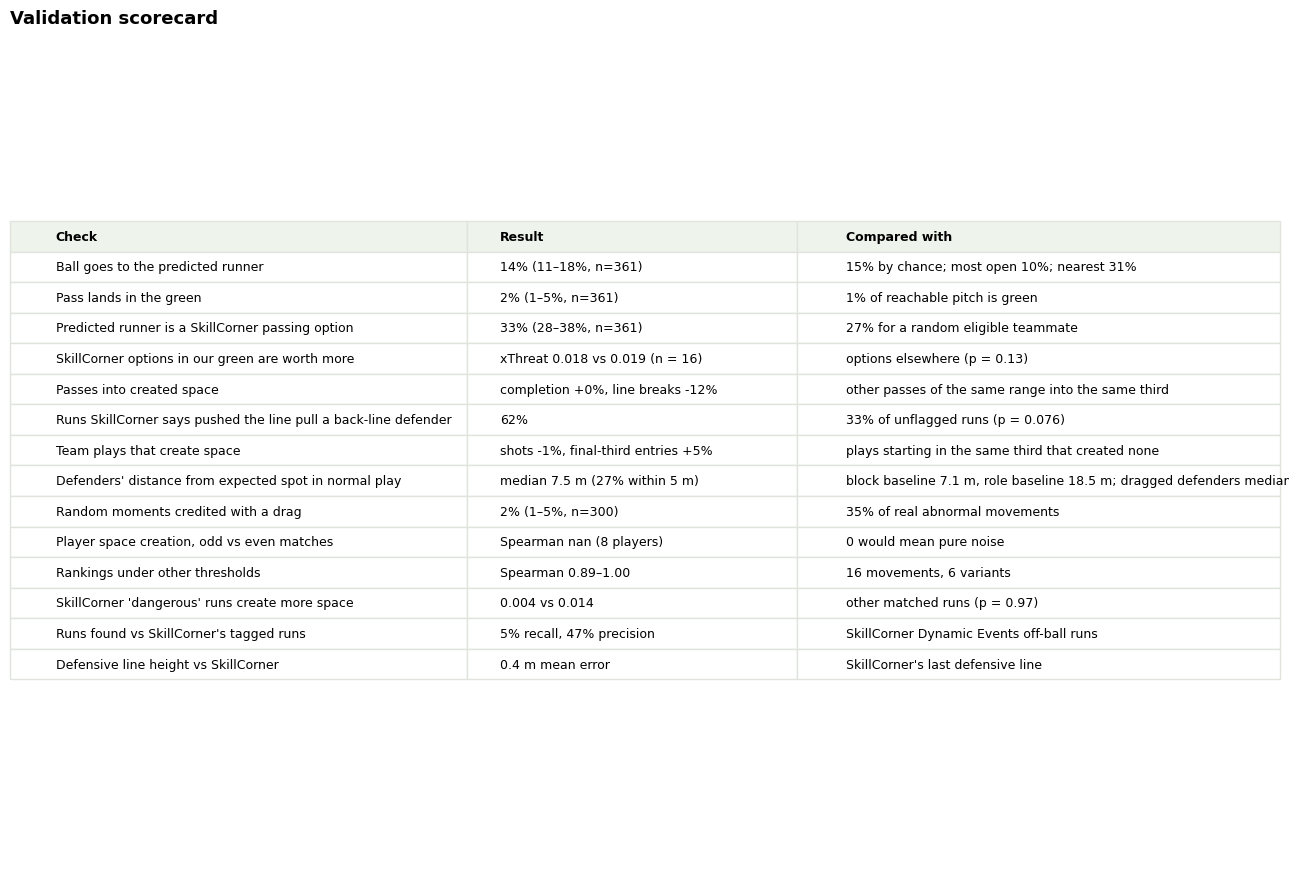

Saved validation results for 1,844 movements to C:\Users\bchm5\TSLR\Analytics Cup\analytics-cup-football\data\outputs\validation_runs.pkl


In [31]:
# Blind review row (if any answers exist)
if SHEET.exists():
    rv = pd.read_csv(SHEET)
    yn = {c: rv[c].dropna().astype(str).str.strip().str.lower().str[0] for c in
          ("dragged_correct", "beneficiary_correct", "movement_real") if c in rv}
    parts = []
    for c, lab in (("dragged_correct", "pulled defenders"), ("beneficiary_correct", "runner into space")):
        s = yn.get(c, pd.Series(dtype=str))
        s = s[s.isin(["y", "n"])]
        if len(s):
            parts.append(f"{lab} {pct_ci(int((s == 'y').sum()), len(s))}")
    if parts:
        add_score("review", "Blind review agrees with the model", "; ".join(parts), "judged before seeing the model",
                  "A person watching the play agrees")

ORDER = ["nextpass", "green", "options", "option_value", "pass_outcomes", "line_flag", "possession", "expected",
         "placebo", "stability", "sensitivity", "dangerous", "detect", "line_height", "review"]
SCORE = pd.DataFrame([SC[k] for k in ORDER if k in SC])
SCORE.to_csv(OUT_DIR / "validation_scorecard.csv", index=False)
display(SCORE)

if len(SCORE):
    fig, ax = plt.subplots(figsize=(13, 0.55 * len(SCORE) + 1.2))
    ax.axis("off")
    t = ax.table(cellText=SCORE[["check", "result", "comparison"]].values,
                 colLabels=["Check", "Result", "Compared with"], loc="center", cellLoc="left", colLoc="left",
                 colWidths=[0.36, 0.26, 0.38])
    t.auto_set_font_size(False)
    t.set_fontsize(9)
    t.scale(1, 1.5)
    for (r, c), cell in t.get_celld().items():
        cell.set_edgecolor("#dfe5dc")
        if r == 0:
            cell.set_text_props(weight="bold")
            cell.set_facecolor("#eef3ec")
    ax.set_title("Validation scorecard", fontsize=13, weight="bold", loc="left")
    fig.tight_layout()
    fig.savefig(VAL_DIR / "scorecard.png", dpi=170, bbox_inches="tight")
    plt.show()

# Per-movement export for the dashboard's Verify filter
VR = RUNS[["match_id", "player_id", "frame_start", "kind", "sk_event_id", "sk_dangerous"]].copy()
VR["sk_event_id"] = VR.sk_event_id.astype(str)
fl = flags.rename(columns={"push_defensive_line": "sk_push_line", "break_defensive_line": "sk_break_line",
                           "event_subtype": "sk_subtype"})
VR = VR.reset_index().merge(fl, on=["match_id", "sk_event_id"], how="left").set_index("index")
if len(EV):
    keep = ["idx", "has_pass", "receiver", "ben_id", "hit_top1", "hit_top2", "receiver_rank", "ben_is_option",
            "into_green", "completed"]
    VR = VR.join(EV[[c for c in keep if c in EV]].set_index("idx"))
if SHEET.exists():
    rv = pd.read_csv(SHEET)
    cols = [c for c in ("case_id", "movement_real", "dragged_correct", "missed_defender", "beneficiary_correct",
                        "data_issue", "notes") if c in rv]
    r2 = rv[["match_id", "frame_start", "kind"] + cols].rename(columns={c: f"review_{c}" for c in cols})
    VR = VR.reset_index().merge(r2, on=["match_id", "frame_start", "kind"], how="left").set_index("index")
VR.to_pickle(OUT_DIR / "validation_runs.pkl")
print(f"Saved validation results for {len(VR):,} movements to {OUT_DIR / 'validation_runs.pkl'}")

## 10. Next steps

* **QC the validation** on real data: look through the dashboard's *Verify* filter (hits, misses, SkillCorner-flagged
  runs, review disagreements) and fix whatever the misses have in common.
* **Second reviewer** on ~20 review cases for Cohen's kappa.
* **Pose** — run Section 3 on both full pose matches; compare decoy vs genuine runs by orientation.
* **Footage** — use the match clocks to pull matching broadcast clips (check competition rules and rights first).